# Самостоятельная работа: dense GAN на Fashion-MNIST

Здесь требуется самостоятельно перенести алгоритм состязательного
обучения на Fashion-MNIST. Данные отличаются от MNIST-примера, но
размер изображения, нормализация, архитектуры и математические цели
остаются теми же. Заголовки описывают этапы; маркеры «TODO(student)»
расположены только в кодовых ячейках.

Выполняйте задания строго по порядку. На каждом этапе сначала
подтвердите форму тензоров и только потом продолжайте. Метки классов
Fashion-MNIST не становятся целями GAN: задача по-прежнему состоит в
различении реального и синтетического изображения.

## История одного пакета

Генератор превращает пачку случайных карточек `(B,100)` в пачку
картинок `(B,784)`. Дискриминатор смотрит и на эти картинки, и на
настоящие предметы одежды, а затем выдаёт по одному числу `(B,1)`.
Сначала учится проверяющий, потом — художник. Выполняйте этапы именно
по порядку: следующий этап использует объекты, созданные и проверенные
на предыдущем.

### Маленький словарь перед реализацией

Параметры — обучаемые числа в слоях. Прямой проход создаёт картинку и
ответ проверяющего. Потеря — одно число, описывающее ошибку текущего
ответа. Градиент — инструкция, как слегка поменять параметры, чтобы
ошибка уменьшилась. `GradientTape` находит такую инструкцию, а Adam
применяет небольшую поправку.

## Этап 1. Конфигурация независимого эксперимента

**Доступно:** константы ниже. **Цель:** зафиксировать Fashion-MNIST,
первые 10 000 изображений, $d_z=100$, $d_x=784$, пакет 128 и
первоначальные 105 эпох. Для сравнений позднее установите 205 и 400
эпох, не меняя остальную постановку. **Контрольная точка:** диапазон
целевых меток GAN — 0.9, 0 и 1; это не метки предметов одежды.

`(B,784)` означает «B картинок, каждая записана длинной строкой из
784 яркостей», а `(B,1)` — один ответ проверяющего на картинку. Это не
784 разных объектов и не десять классов Fashion-MNIST.

In [1]:
from __future__ import annotations

# Path указывает только место для сеток и графиков. NumPy/Matplotlib
# обслуживают данные и диагностику; TensorFlow строит граф и модели.
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf

# Зафиксируйте seed до первого шума и создания слоёв, иначе два
# запуска нельзя будет сравнивать по одним и тем же условиям.
SEED = 42
DATASET_NAME = 'Fashion-MNIST'
MAX_EXAMPLES = 10_000
IMAGE_HEIGHT = 28
IMAGE_WIDTH = 28
# Размерность dense-входа: каждая карта 28×28 станет длиной 784.
IMAGE_DIM = IMAGE_HEIGHT * IMAGE_WIDTH
NOISE_DIM = 100
BATCH_SIZE = 128
EPOCHS = 105
LEARNING_RATE = 2e-4
BETA_1 = 0.5
REAL_LABEL = 0.9
FAKE_LABEL = 0.0
GENERATOR_TARGET = 1.0
SAVE_EVERY = 20

# Keras использует генератор случайных чисел и для весов, и для z.
tf.keras.utils.set_random_seed(SEED)
artifact_dir = Path('artifacts/fashion_mnist_dense_gan')
artifact_dir.mkdir(parents=True, exist_ok=True)
print("TensorFlow:",tf.__version__,"GPU:",tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0 GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## Этап 2. Получение и подготовка Fashion-MNIST

**Требуется:** получить обучающие изображения Fashion-MNIST, оставить
первые 10 000, преобразовать пиксели из $[0,255]$ в $[-1,1]$ и
развернуть их в $(N,784)$. Затем создайте перемешиваемый набор
мини-пакетов $(B,784)$ без меток классов. **Проверьте:** значения
конечны и принадлежат $[-1,1]$; метки используются только для
необязательной подписи исходных изображений.

**Маршрут:** сначала загрузите массив и посмотрите на одну картинку,
затем приведите значения к `float32`, измените шкалу `[0,255] → [-1,1]`
и лишь потом разверните карту. Останавливайтесь на `assert`: при
неверной форме или диапазоне сеть строить ещё рано. `y_train` не
передаётся GAN, иначе это была бы задача классификации одежды.

In [2]:
(x_train,y_train),_=tf.keras.datasets.fashion_mnist.load_data()
x_train=x_train[:MAX_EXAMPLES].astype(np.float32).reshape(-1,IMAGE_DIM)/127.5-1
y_train=y_train[:MAX_EXAMPLES]
dataset=tf.data.Dataset.from_tensor_slices(x_train).shuffle(MAX_EXAMPLES,seed=SEED).batch(BATCH_SIZE)
assert x_train.shape==(MAX_EXAMPLES,IMAGE_DIM) and np.isfinite(x_train).all()
assert x_train.min()>=-1 and x_train.max()<=1
print(x_train.shape,x_train.min(),x_train.max(),next(iter(dataset)).shape)

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 1us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
(10000, 784) -1.0 1.0 (128, 784)


## Этап 3. Генератор и проверка его выхода

**Требуется:** собрать генератор
$100\to256\to512\to1024\to784$ с тремя LeakyReLU и финальным tanh.
Вход — шум $(B,100)$ с независимыми нормальными координатами; выход —
синтетические развёрнутые изображения $(B,784)$ в $[-1,1]$.
Используйте современный tf.keras и не применяйте готовый GAN-слой.
**Контрольная точка:** выход имеет точную форму и не содержит NaN или
бесконечностей.

Считайте `z` карточкой со 100 случайными ручками. В начале генератор
рисует бессмыслицу; обучение понемногу поправляет его веса, чтобы те
же 100 чисел превращались в структуру, похожую на данные. `tanh` не
даёт пикселям покинуть диапазон настоящих картинок.

In [3]:
def make_generator():
    layers=[tf.keras.layers.Input((NOISE_DIM,))]
    for units in (256,512,1024):
        layers += [tf.keras.layers.Dense(units,kernel_initializer=tf.keras.initializers.RandomNormal(stddev=0.02)),tf.keras.layers.LeakyReLU(negative_slope=0.2)]
    layers += [tf.keras.layers.Dense(IMAGE_DIM,activation='tanh',kernel_initializer=tf.keras.initializers.RandomNormal(stddev=0.02))]
    return tf.keras.Sequential(layers)
generator=make_generator()
z=tf.random.normal((BATCH_SIZE,NOISE_DIM)); fake=generator(z,training=False)
assert fake.shape==(BATCH_SIZE,IMAGE_DIM) and np.isfinite(fake.numpy()).all()
assert np.max(np.abs(fake.numpy()))<=1
print('G(z):',fake.shape)

G(z): (128, 784)


## Этап 4. Дискриминатор и смысл его выхода

**Требуется:** собрать дискриминатор
$784\to1024\to512\to256\to1$ с LeakyReLU, Dropout(0.3) и sigmoid.
Его входом по очереди будут настоящие и синтетические изображения
$(B,784)$, а результатом — $(B,1)$ вероятностей. Последняя координата
— не класс Fashion-MNIST, а оценка «настоящее».
**Контрольная точка:** на диагностическом входе значения строго между
0 и 1.

Единственный вопрос дискриминатора — «эта картинка пришла из набора
или создана генератором?». Его ответ после sigmoid можно читать как
уверенность от 0 до 1. Это совсем не вероятность одного из классов
одежды и не оценка того, насколько красив предмет.

In [4]:
def make_discriminator():
    layers=[tf.keras.layers.Input((IMAGE_DIM,))]
    for units in (1024,512,256):
        layers += [tf.keras.layers.Dense(units,kernel_initializer=tf.keras.initializers.RandomNormal(stddev=0.02)),tf.keras.layers.LeakyReLU(negative_slope=0.2),tf.keras.layers.Dropout(0.3)]
    layers += [tf.keras.layers.Dense(1,activation='sigmoid',kernel_initializer=tf.keras.initializers.RandomNormal(stddev=0.02))]
    return tf.keras.Sequential(layers)
discriminator=make_discriminator()
for x in (next(iter(dataset)),fake):
    score=discriminator(x,training=False).numpy(); assert score.shape==(BATCH_SIZE,1) and np.isfinite(score).all() and ((score>0)&(score<1)).all()
    print('D(x):',score.shape,score.min(),score.max())

D(x): (128, 1) 0.4867486 0.49896872
D(x): (128, 1) 0.4998919 0.50000614


## Этап 5. Две функции потерь и два независимых обновления

**Требуется:** создать BinaryCrossentropy с «from_logits=False» и два
Adam-оптимизатора с заданными learning_rate и beta_1. Напишите
попеременный шаг: сначала обновляет только дискриминатор по настоящим
меткам 0.9 и синтетическим 0; затем обновляет только генератор по
цели 1. Для первого шага отделите синтетические изображения от
градиента генератора. Для второго вызовите дискриминатор с
«training=False», но сохраните прохождение градиента к генератору.

**Контрольная точка:** после первого подшага меняются только
переменные дискриминатора, после второго — только переменные
генератора. Обе потери должны быть конечными скалярами.

**Сначала → затем → проверить.** Сначала выполните фазу D и отделите
созданные картинки через `stop_gradient`: обратная стрелка к G
выключена. Затем создайте новый `GradientTape` для фазы G: стрелка от
ошибки идёт через D к G, но список параметров оптимизатора содержит
только G. Визуальная проверка проста: спросите, какие веса стоят справа
в каждом вызове `apply_gradients`.

Здесь D возвращает вероятность $p$ после sigmoid. Для одной цели $y$
API `BinaryCrossentropy(from_logits=False)` использует

$$
\operatorname{BCE}(y,p)=-y\log p-(1-y)\log(1-p).
$$

Неправильный уверенный ответ получает большую потерю; правильный
уверенный ответ — малую. Для всего мини-пакета TensorFlow усредняет
эту ошибку, получая один скаляр для каждого игрока.

### Математический контракт вашей реализации

**Сначала посмотрите на две фазы глазами данных.**

![Два независимых обновления GAN: обучение дискриминатора, затем обучение генератора](assets/diagrams/gan_two_phase_training.svg)

Эта схема разделяет временные тензоры, скалярные потери и параметры.
Ваша будущая функция не должна пытаться «обучать шум» или метки
Fashion-MNIST: шум — вход, а метки классов вообще не участвуют в GAN.
Обучаемыми остаются только `tf.Variable` внутри G и D.

Обозначим веса и смещения генератора через $\theta_G$, а параметры
дискриминатора — через $\theta_D$. Потеря — один скаляр. Производная
по параметру показывает направление его маленькой поправки:

$$
\theta\leftarrow\theta-\eta\nabla_\theta\mathcal L.
$$

В первой фазе для мини-пакета должны быть вычислены два члена
$\operatorname{BCE}(0.9,D(\mathbf x_{\rm real}))$ и
$\operatorname{BCE}(0,D(G(\mathbf z_D)))$; их среднее образует
$\mathcal L_D$, а градиент запрашивается только по $\theta_D$.
Во второй фазе $\mathcal L_G=\operatorname{BCE}(1,D(G(\mathbf z_G)))$
дифференцируется только по $\theta_G$. Шум — не параметр: каждый
$\mathbf z$ является новым входом формы `(B,100)`.

### Как `GradientTape` превращает loss в поправки весов

![Жизненный цикл GradientTape от прямого прохода до обновления Adam](assets/diagrams/tensorflow_gradient_tape.svg)

`GradientTape` записывает прямой путь вычислений до `loss`, а не
делает отдельное обучение. Пока активен блок `with`, он помнит
дифференцируемые операции и автоматически наблюдает используемые
обучаемые `tf.Variable`. Затем `tape.gradient(loss, variables)`
запускает обратный проход и возвращает по одной производной для
каждого элемента `variables`; форма градиента совпадает с формой
веса. `zip` сопоставляет эти два списка, а `apply_gradients` передаёт
пары Adam. Именно `variables` определяет, обновляется $\theta_G$ или
$\theta_D$; имя tape этого решения не принимает.

Непостоянный tape имеет одно назначение: он нужен для одного вызова
`gradient`, затем его запись освобождается. Это программная запись
правила градиентного шага, а не эвристика TensorFlow. Производные
получаются по цепному правилу: библиотека не выписывает гигантские
якобианы, а передаёт их нужное действие от скалярной потери к весам.

### Один мини-пакет: карта объектов вашей реализации

Используйте эти имена как ориентиры при заполнении TODO. Объекты с
пометкой «временный» не являются параметрами и не передаются Adam.

| Математика | Ожидаемое имя | Форма | Роль в одной фазе |
| --- | --- | --- | --- |
| $\mathbf x_{\rm real}$ | `real_images` | `(B,784)`, `float32` | Настоящие картинки для D. |
| $\mathbf z_D$ | `discriminator_noise` | `(B,100)` | Временный шум фазы D. |
| $G(\mathbf z_D)$ | `fake_images` | `(B,784)` | Подделки после `stop_gradient`. |
| $D(\mathbf x)$ | `real_scores`, `fake_scores` | `(B,1)`, вероятность | Аргумент BCE фазы D. |
| $\mathcal L_D$ | `discriminator_loss` | скаляр | Даёт градиенты только для `discriminator.trainable_variables`. |
| $\mathbf z_G$ | `generator_noise` | `(B,100)` | Новый шум, независимый от $\mathbf z_D$. |
| $G(\mathbf z_G)$ | `generated_images` | `(B,784)` | Подделки, оставленные в графе. |
| $\mathcal L_G$ | `generator_loss` | скаляр | Даёт градиенты только для `generator.trainable_variables`. |

**Проведите одну фазу буквально по строкам.** Сначала внутри первого
`GradientTape` вычисляются входы D и один скаляр `discriminator_loss`.
Затем `tape.gradient(discriminator_loss,
discriminator.trainable_variables)` строит список производных в том же
порядке, что список весов. `zip` образует пары, и только после
`discriminator_optimizer.apply_gradients(...)` меняются $\theta_D$.
Фаза G повторяет эту схему с новым tape, новым шумом и списком весов G.

Для этой модели D выдаёт вероятность, поэтому точный путь градиента
генератора можно записать через якобианы:

$$
\nabla_{\theta_G}\mathcal L_G
=J_{G,\theta_G}^{\mathsf T}J_{D,\mathbf x}^{\mathsf T}
\nabla_{\mathbf p}\mathcal L_G.
$$

Якобиан — таблица всех локальных влияний: как выход меняется при малом
изменении входа. Он слишком велик для явного создания; `gradient`
вычисляет только нужный обратный проход, то есть произведения с ним.

In [5]:
LOGITS=False

import time, json
from IPython.display import display, Markdown

def make_step(generator, discriminator):
    bce = tf.keras.losses.BinaryCrossentropy(from_logits=LOGITS)
    opt_g = tf.keras.optimizers.Adam(LEARNING_RATE, beta_1=BETA_1)
    opt_d = tf.keras.optimizers.Adam(LEARNING_RATE, beta_1=BETA_1)
    @tf.function
    def d_step(real):
        z = tf.random.normal([tf.shape(real)[0], NOISE_DIM])
        fake = tf.stop_gradient(generator(z, training=False))
        with tf.GradientTape() as tape:
            r = discriminator(real, training=True)
            f = discriminator(fake, training=True)
            loss = 0.5*(bce(tf.ones_like(r)*REAL_LABEL,r)+bce(tf.zeros_like(f),f))
        tf.debugging.assert_all_finite(loss,'D loss')
        opt_d.apply_gradients(zip(tape.gradient(loss,discriminator.trainable_variables),discriminator.trainable_variables))
        return loss
    @tf.function
    def g_step(real):
        z = tf.random.normal([tf.shape(real)[0], NOISE_DIM])
        with tf.GradientTape() as tape:
            f = discriminator(generator(z, training=True), training=False)
            loss = bce(tf.ones_like(f),f)
        tf.debugging.assert_all_finite(loss,'G loss')
        opt_g.apply_gradients(zip(tape.gradient(loss,generator.trainable_variables),generator.trainable_variables))
        return loss
    def train_step(real):
        return d_step(real),g_step(real)
    return train_step,d_step,g_step

# Проверяем фазы на отдельной паре моделей, не меняя стартовые веса эксперимента.
g_test,d_test=make_generator(),make_discriminator()
_,ds,gs=make_step(g_test,d_test)
real=next(iter(dataset))
def snapshot(model): return [v.numpy().copy() for v in model.weights]
def unchanged(old,model): return all(np.array_equal(a,b.numpy()) for a,b in zip(old,model.weights))
g0,d0=snapshot(g_test),snapshot(d_test)
print('D loss (диагностика):',float(ds(real)))
assert unchanged(g0,g_test) and not unchanged(d0,d_test)
g0,d0=snapshot(g_test),snapshot(d_test)
print('G loss (диагностика):',float(gs(real)))
assert unchanged(d0,d_test) and not unchanged(g0,g_test)
print('Раздельное обновление подтверждено')
del g_test,d_test,ds,gs,_

D loss (диагностика): 0.6910051107406616
G loss (диагностика): 0.6934068202972412
Раздельное обновление подтверждено


## Этап 6. Эксперименты, сетки и отчёт

**Требуется:** обучите GAN сначала 105 эпох. На фиксированных 100
шумовых векторах сохраните сетки после первой эпохи, далее через
равные интервалы и в конце. Постройте отдельные ряды потерь
дискриминатора и генератора. Затем повторите запуск для 205 и 400 эпох
с теми же архитектурой, шумом, размером выборки и способом
визуализации.

**Проверка:** все значения потерь конечны; формы не меняются;
изображения становятся разнообразнее или обнаруживаются и
объясняются признаки неустойчивости. В отчёте сравните три режима, не
объявляя меньшую потерю одной стороны безусловной победой GAN.

Фиксированный шум — одинаковый набор заданий для художника. Показывая
его после нескольких эпох, вы видите изменение весов, а не новую
случайную карточку. Для Matplotlib значения возвращаются из `[-1,1]`
в `[0,1]`: модель при этом не меняется. Кривые потерь читайте вместе с
сетками, потому что GAN — соревнование, а не одна убывающая ошибка.

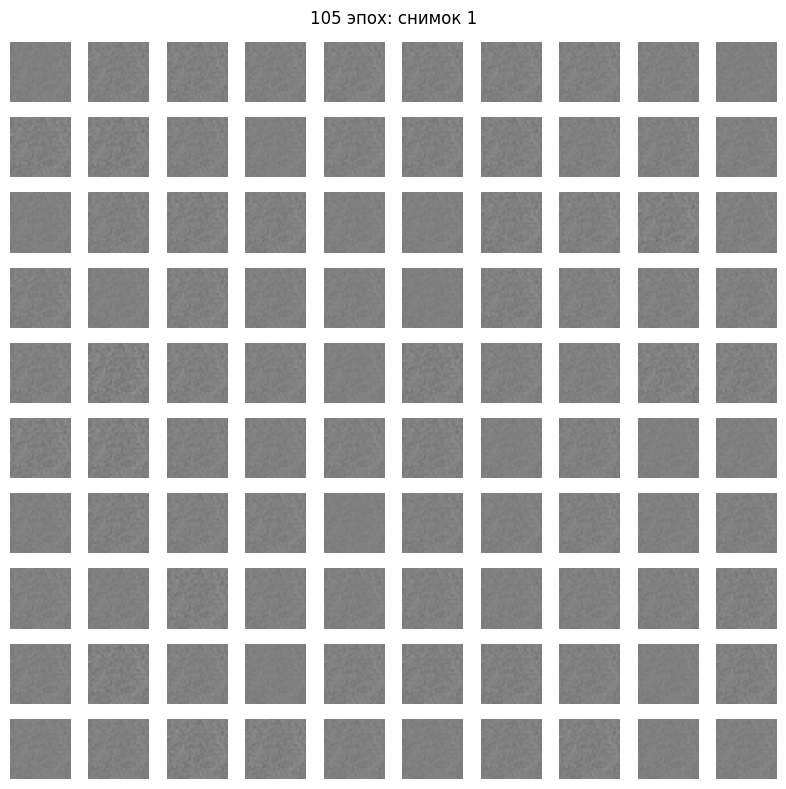

1/105: D=0.53051, G=0.77625


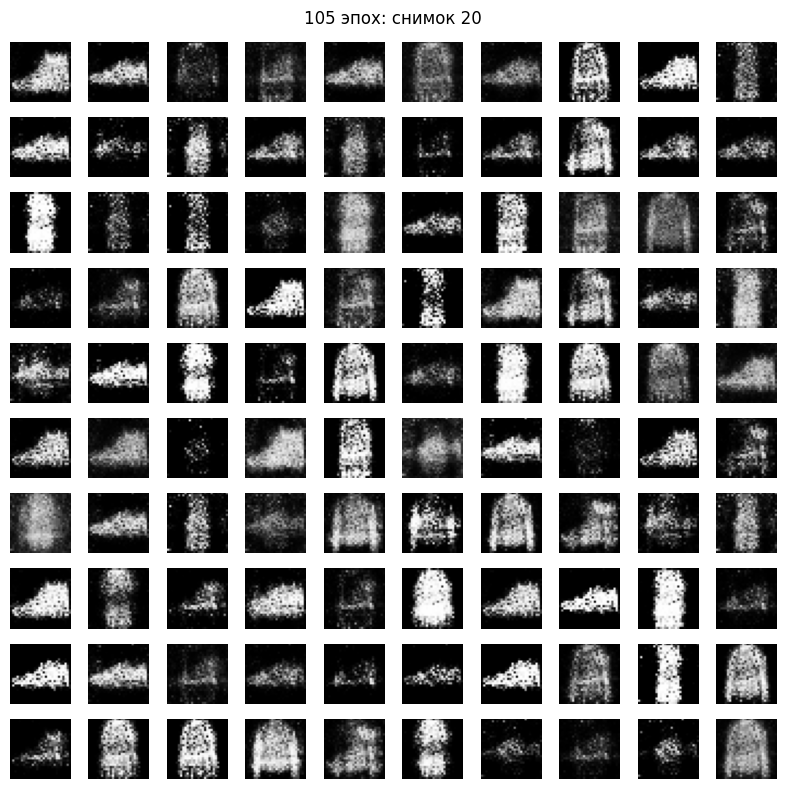

20/105: D=0.47259, G=2.29448


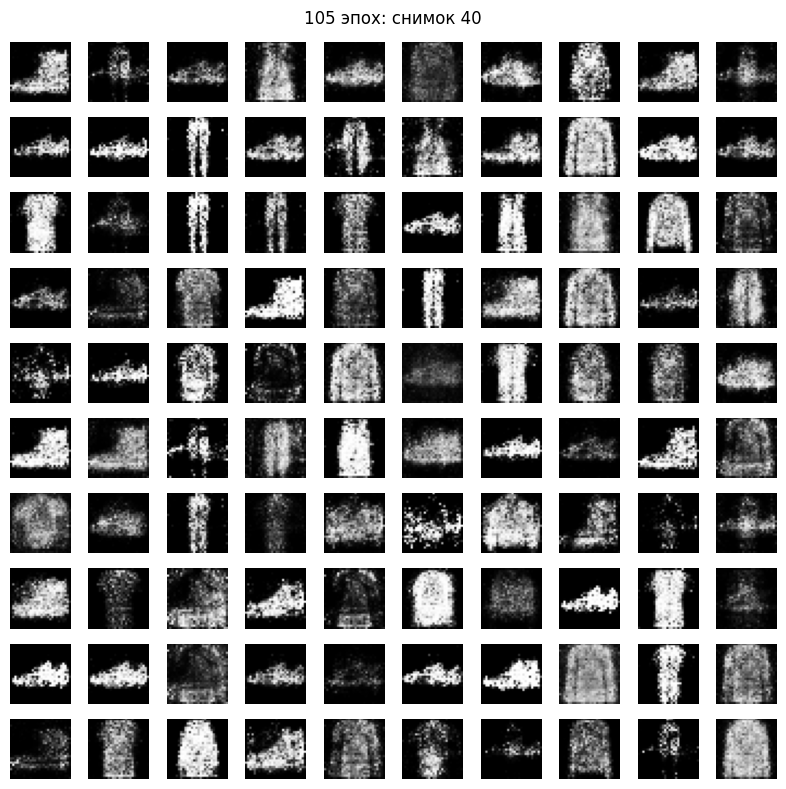

40/105: D=0.54507, G=1.74391


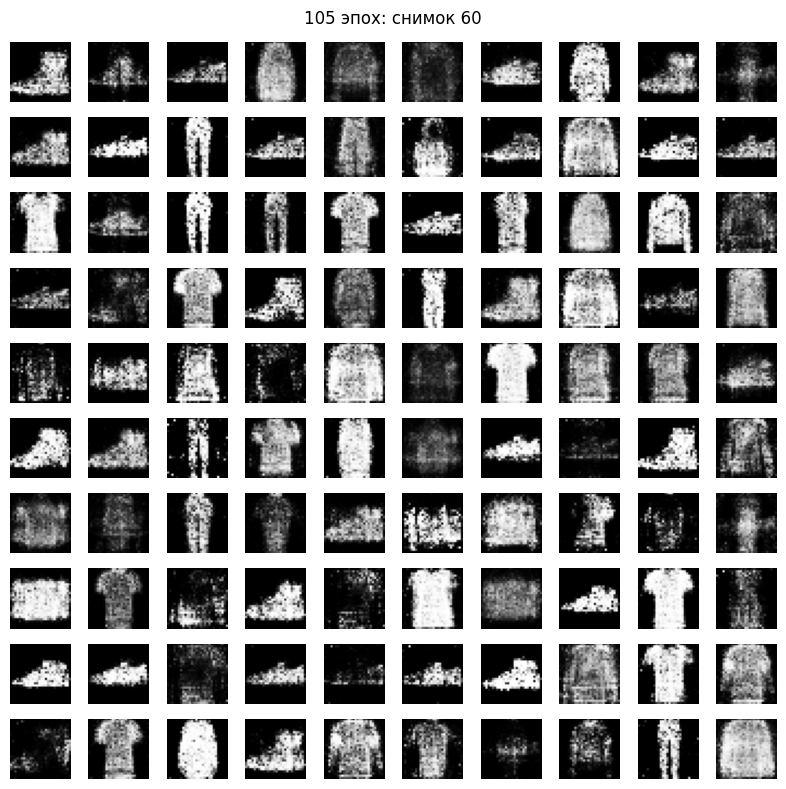

60/105: D=0.57345, G=1.48630


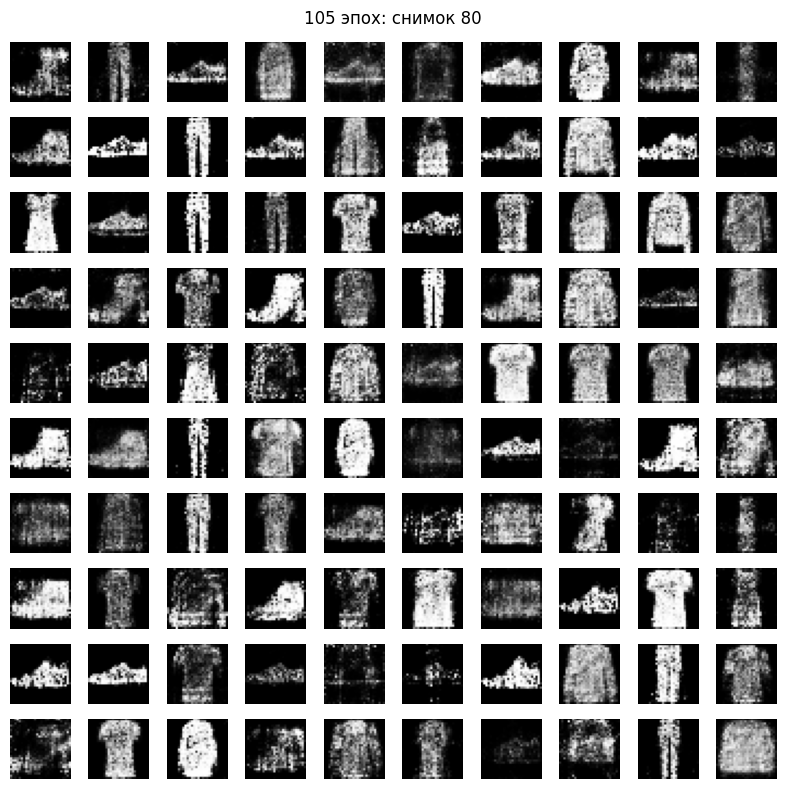

80/105: D=0.60273, G=1.33082


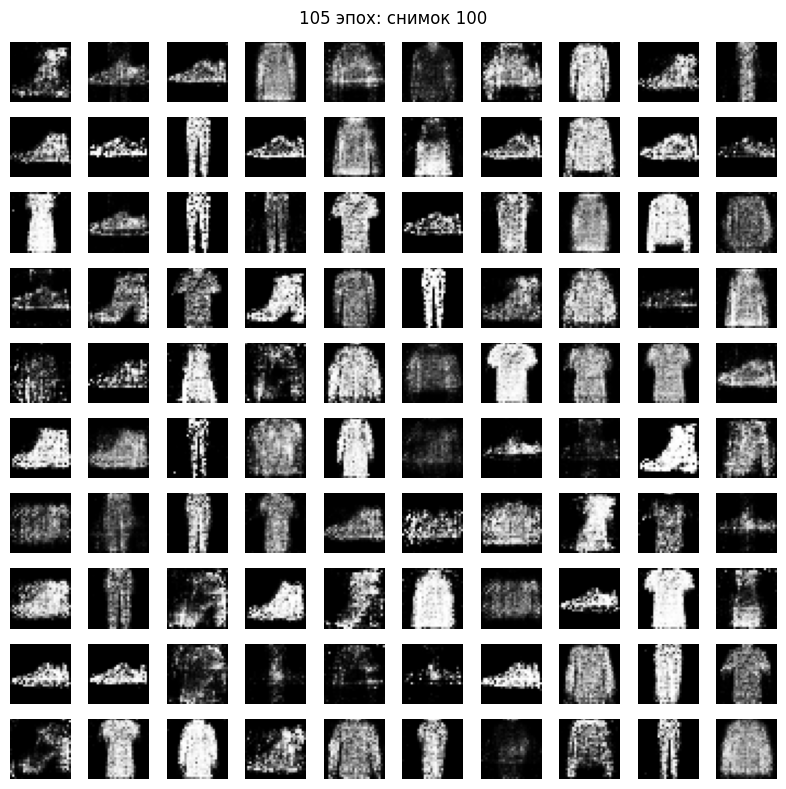

100/105: D=0.61231, G=1.26233


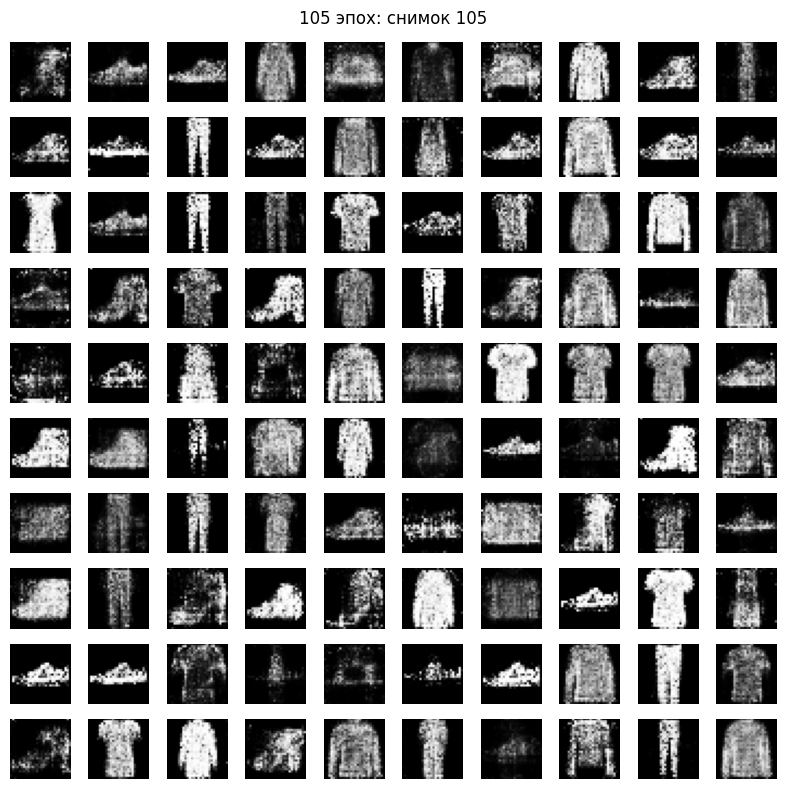

105/105: D=0.61703, G=1.24228


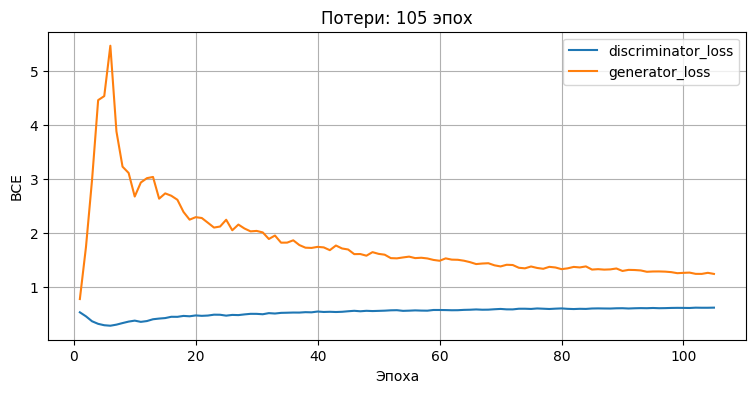

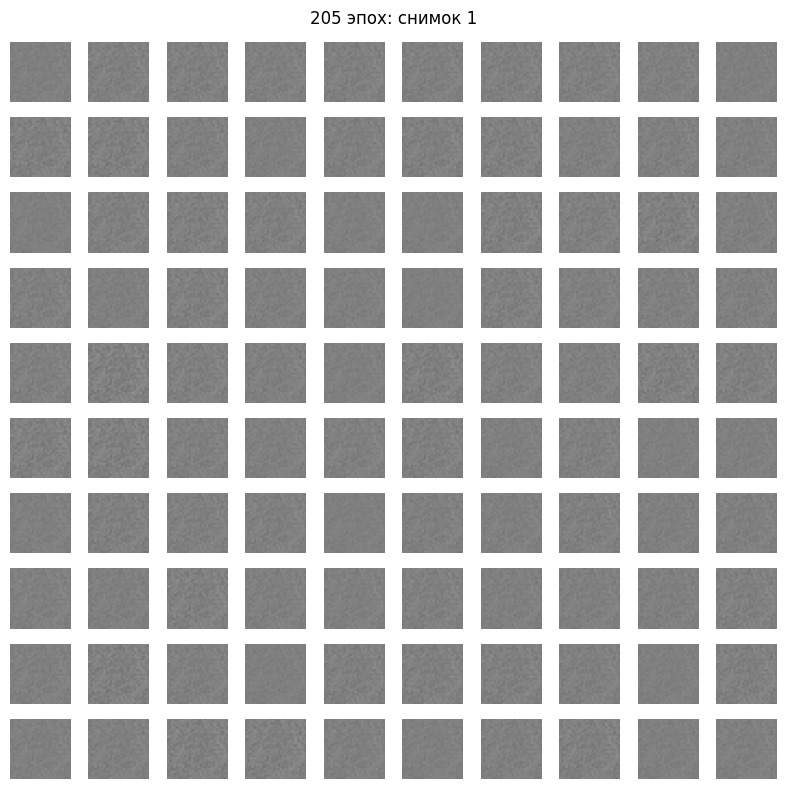

1/205: D=0.53054, G=0.77624


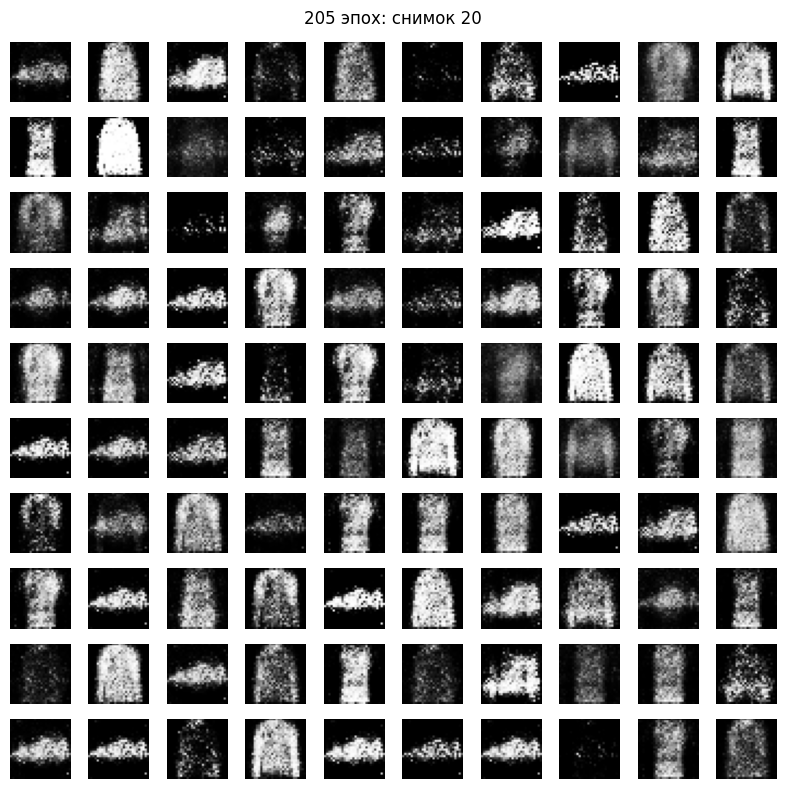

20/205: D=0.46777, G=2.33714


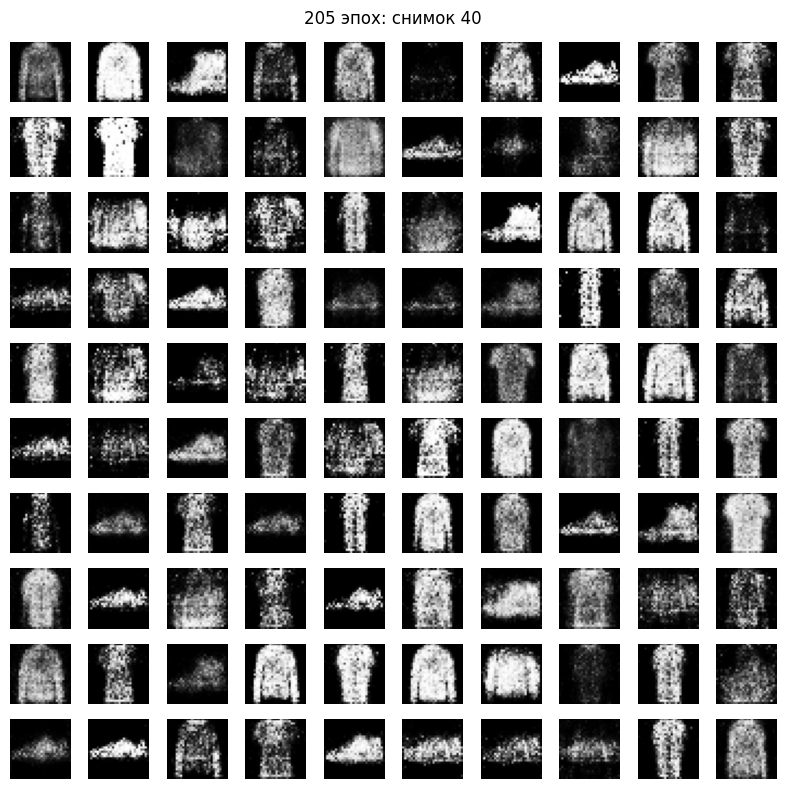

40/205: D=0.52172, G=1.86753


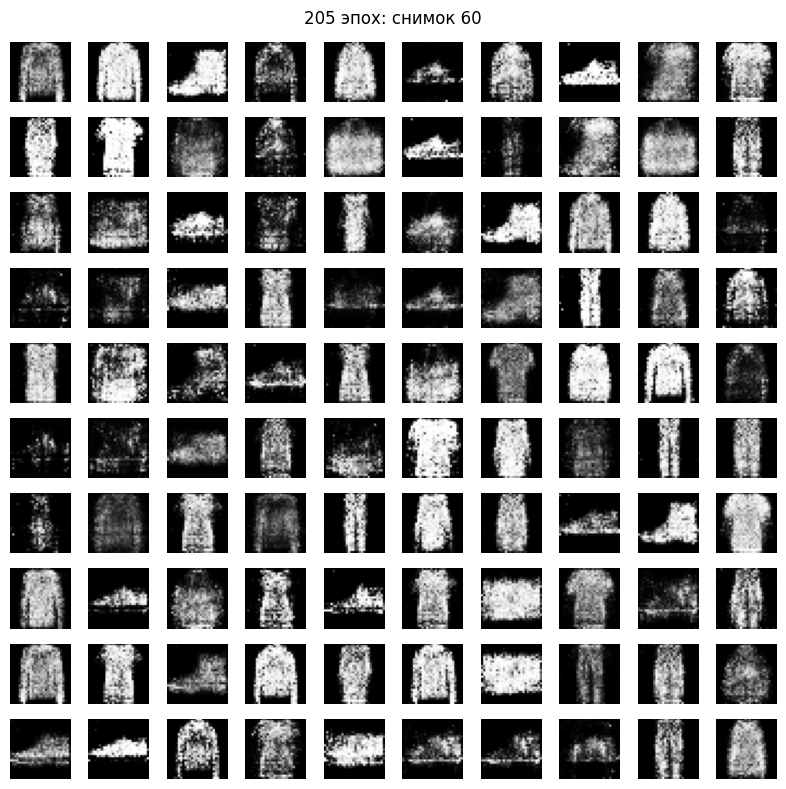

60/205: D=0.57782, G=1.44069


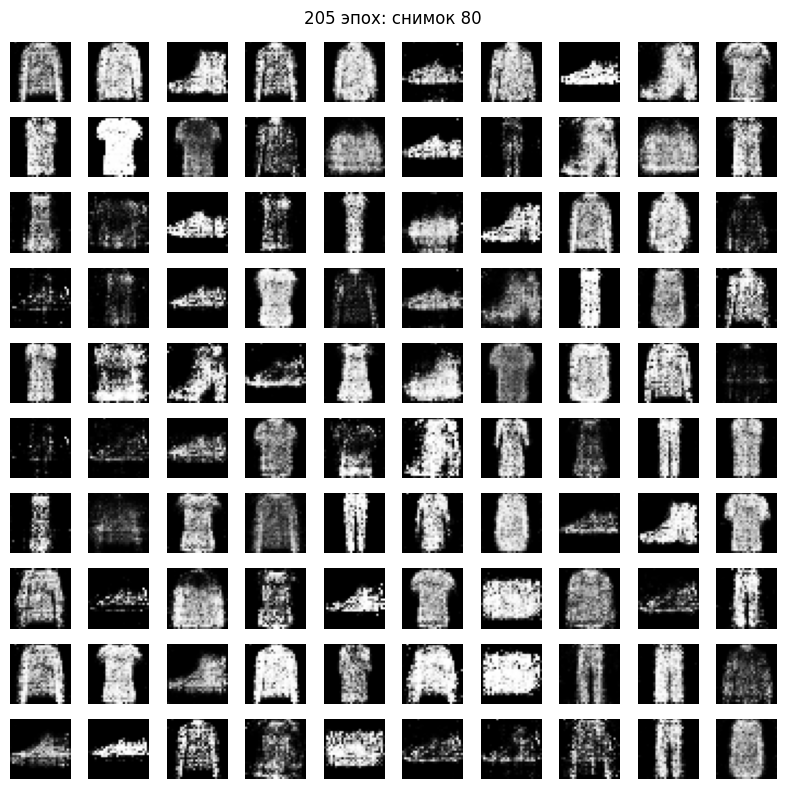

80/205: D=0.59895, G=1.34230


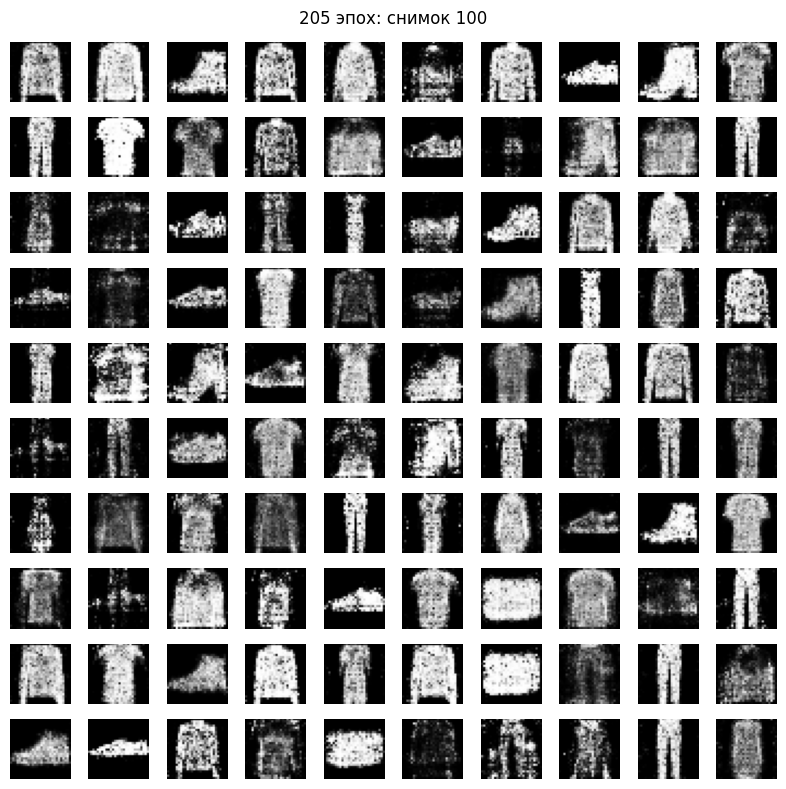

100/205: D=0.61726, G=1.25680


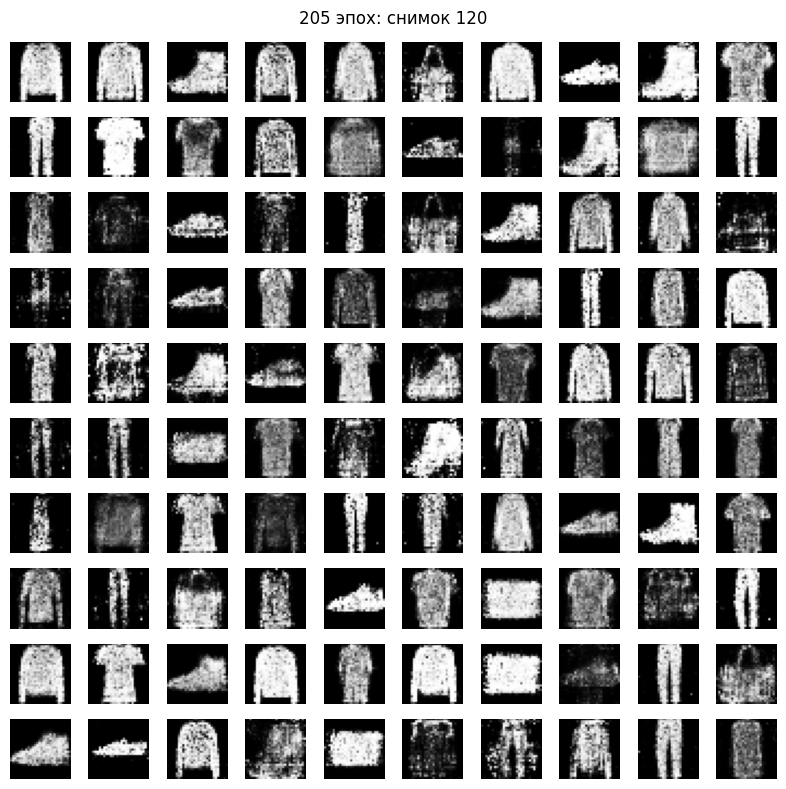

120/205: D=0.62271, G=1.22928


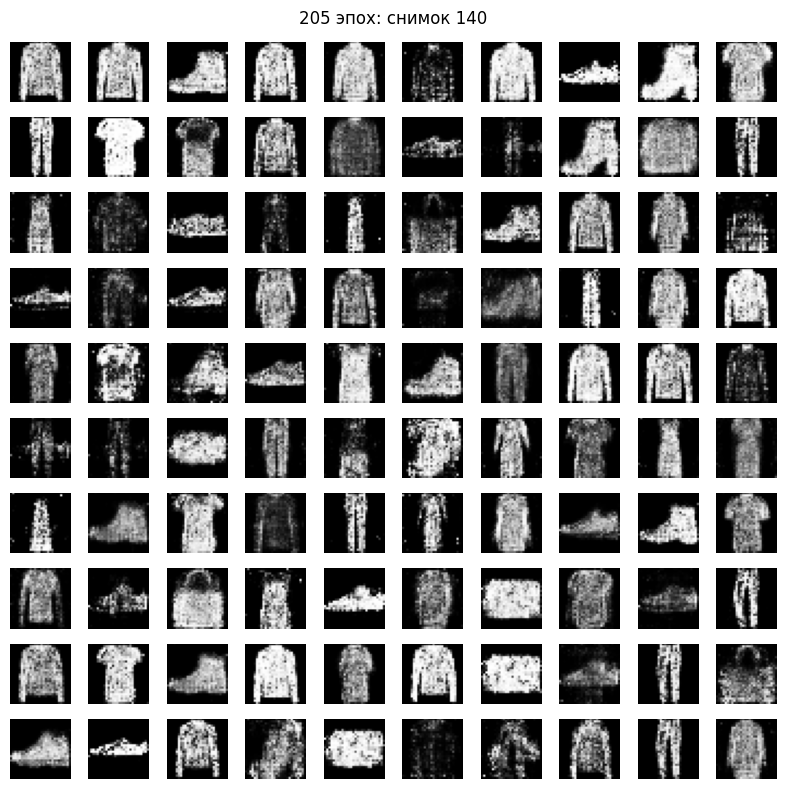

140/205: D=0.63043, G=1.16480


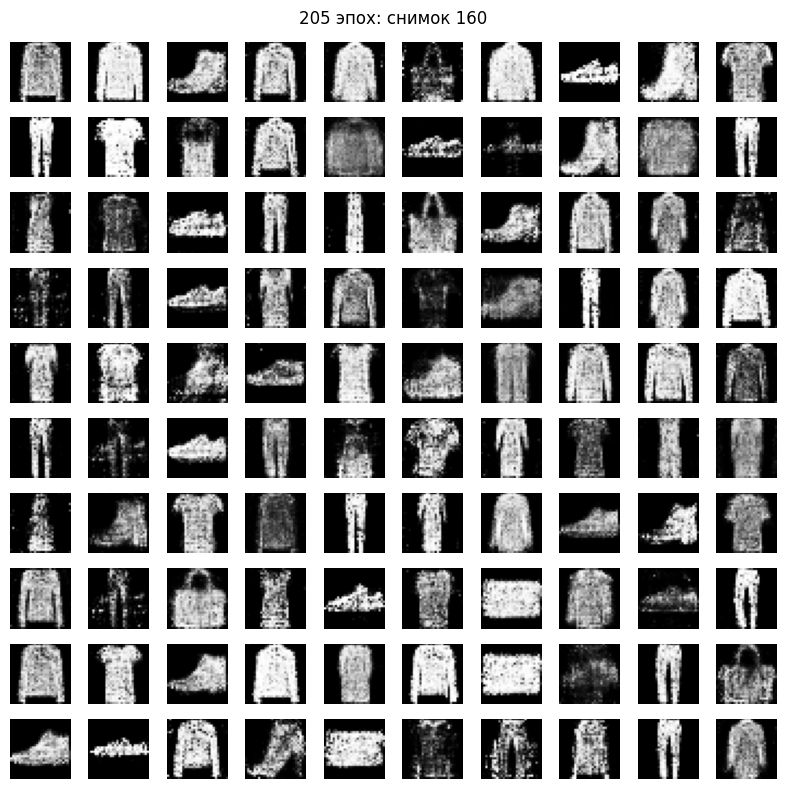

160/205: D=0.63246, G=1.13710


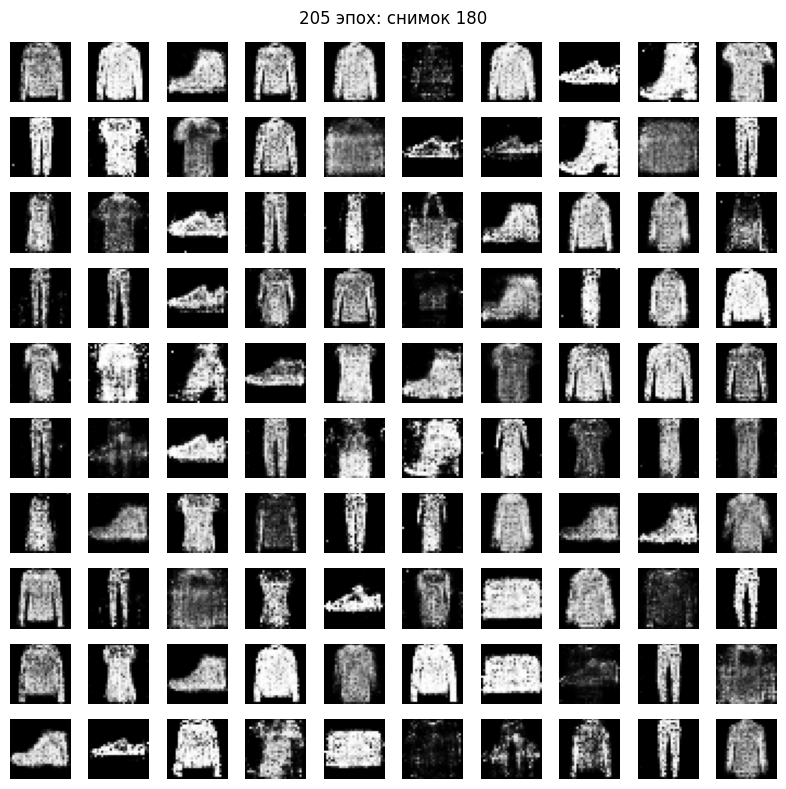

180/205: D=0.63447, G=1.13293


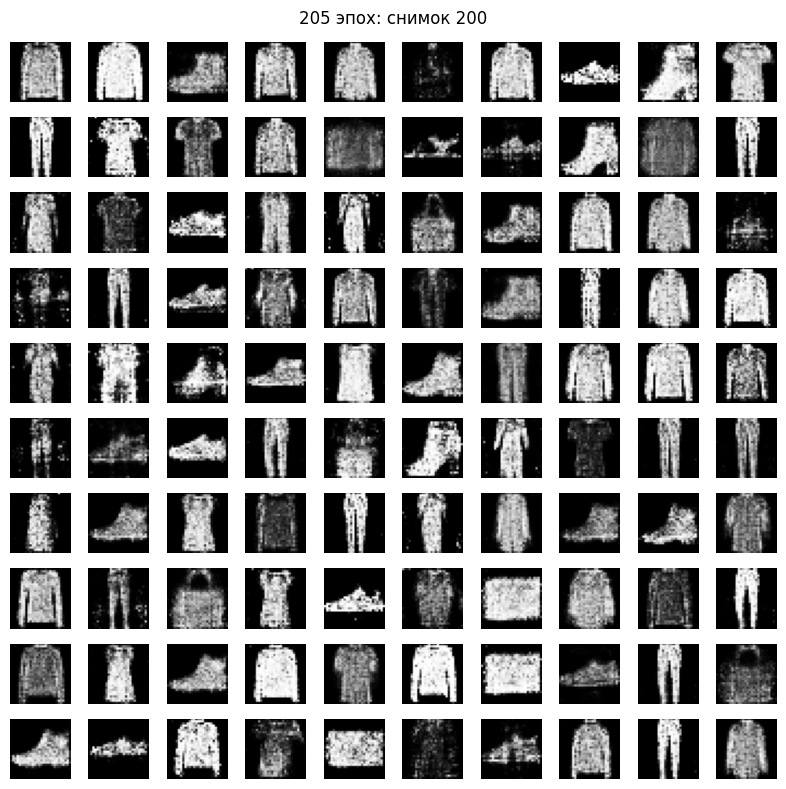

200/205: D=0.63717, G=1.10666


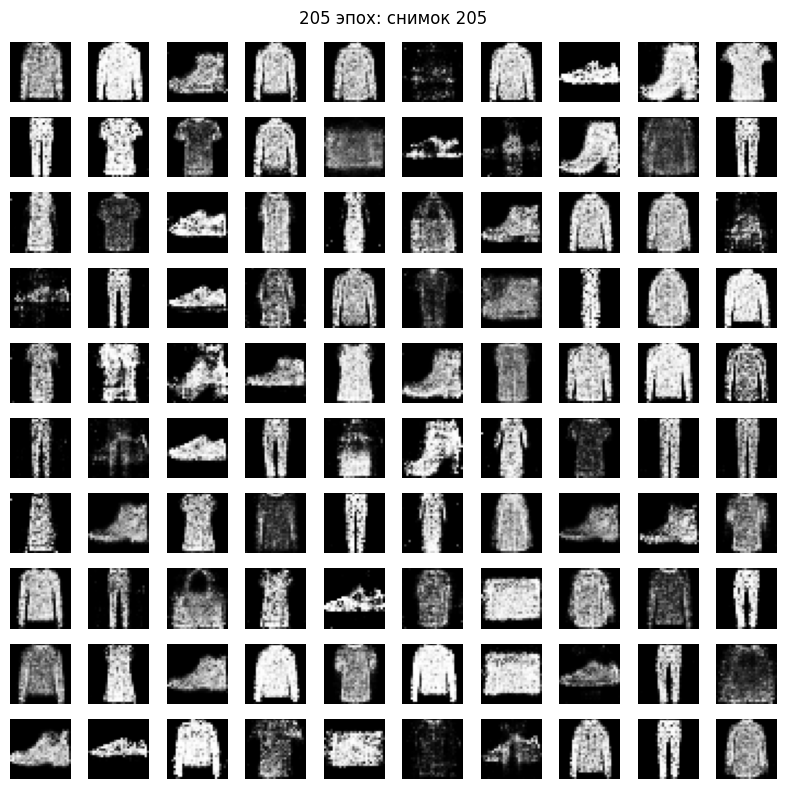

205/205: D=0.63853, G=1.11719


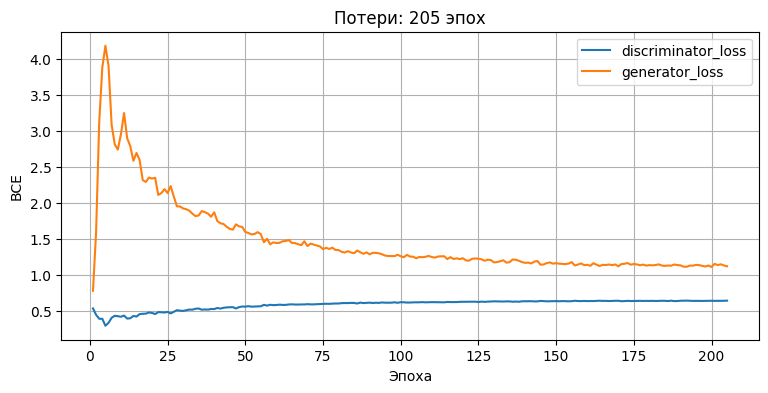

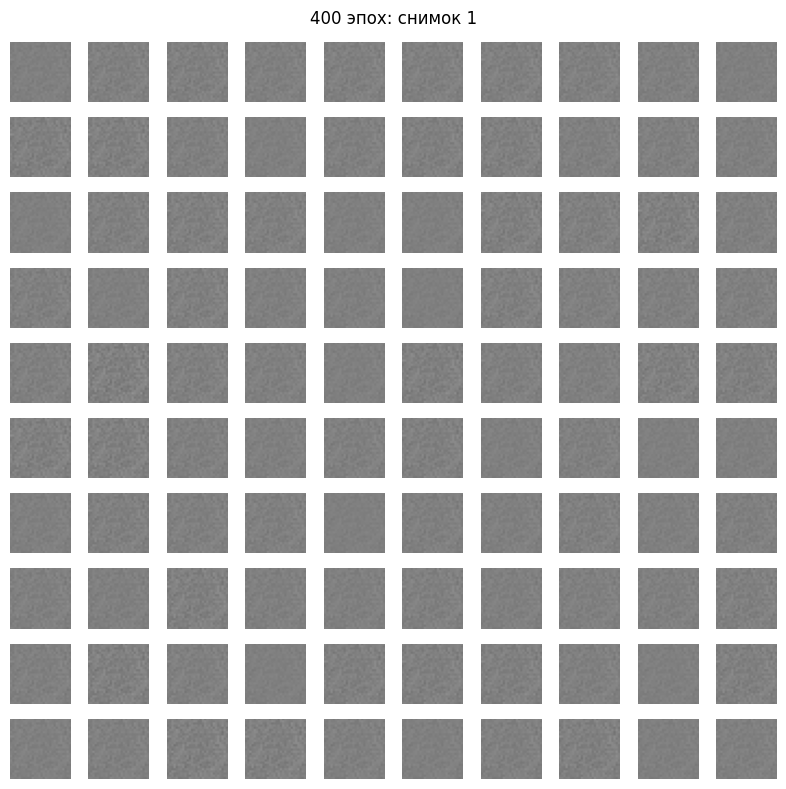

1/400: D=0.53055, G=0.77624


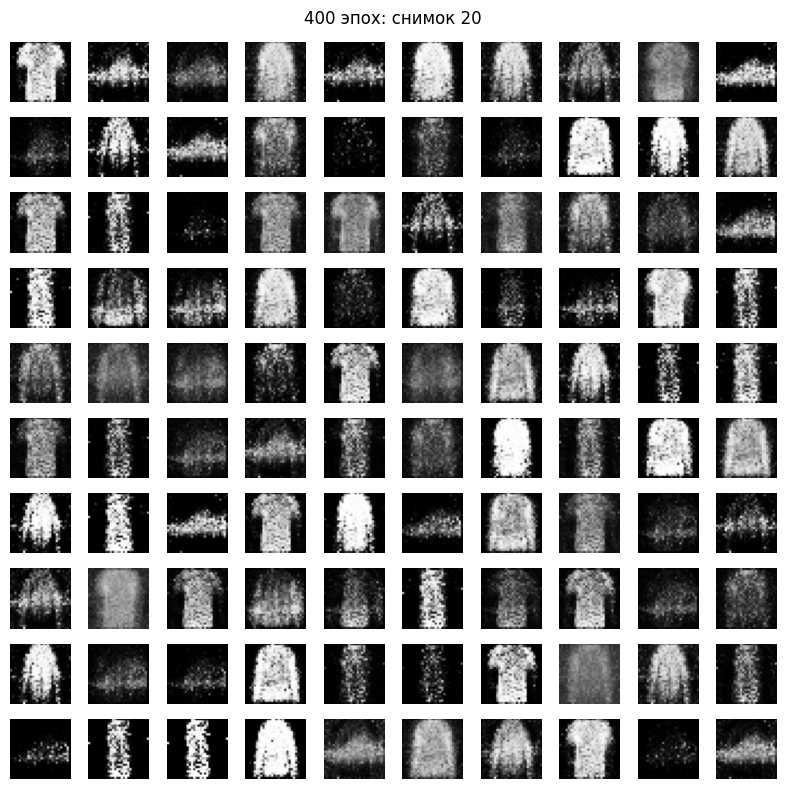

20/400: D=0.46407, G=2.16024


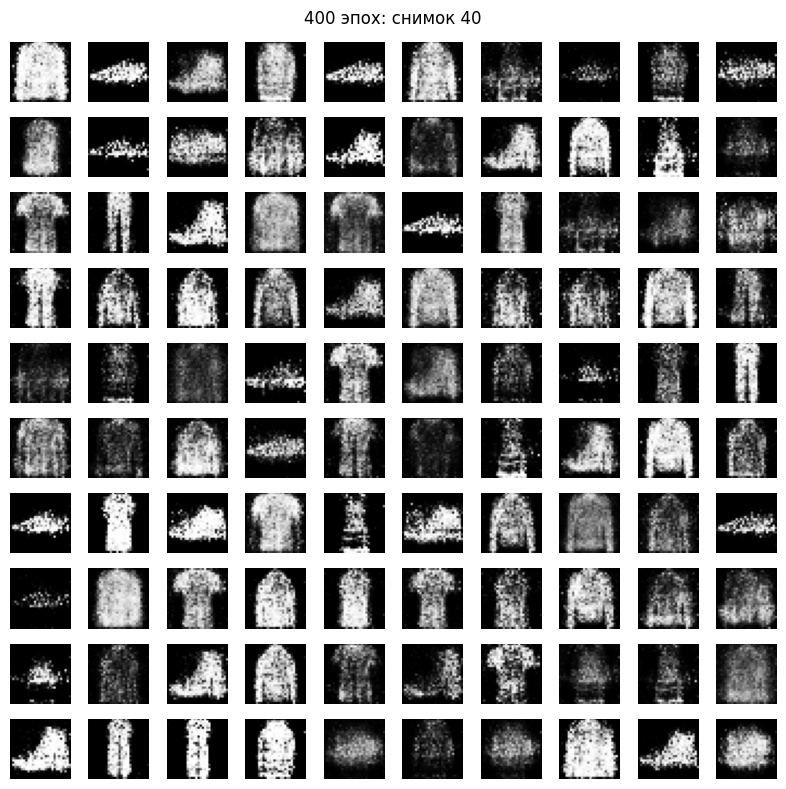

40/400: D=0.52652, G=1.80471


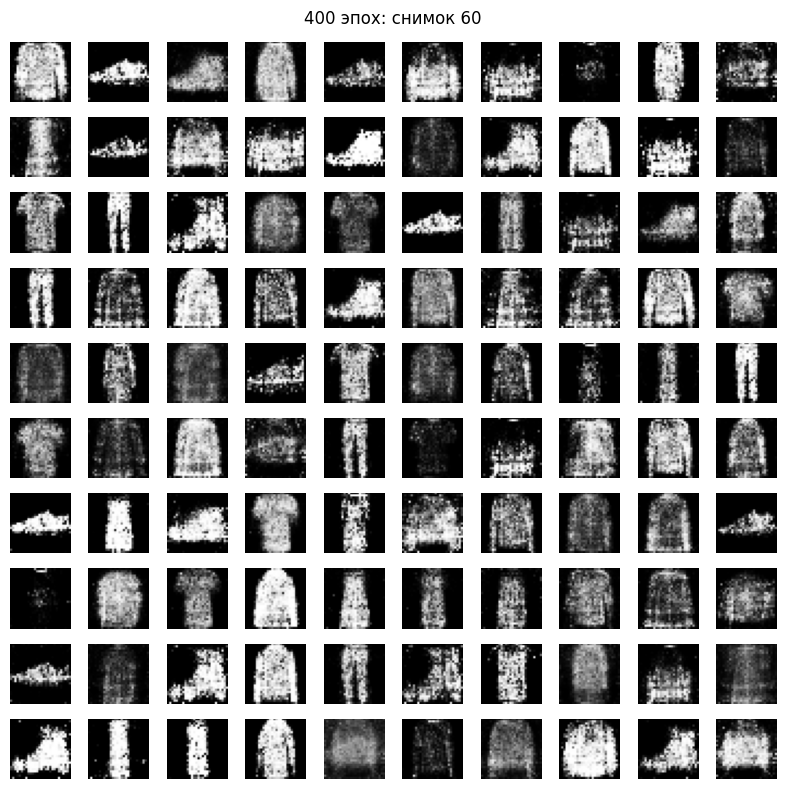

60/400: D=0.56913, G=1.50433


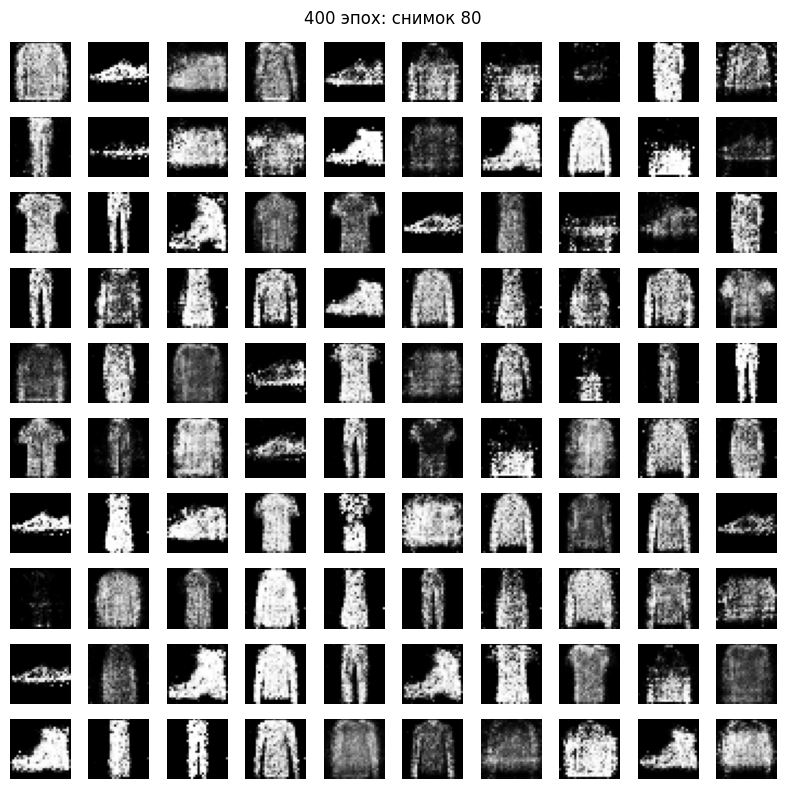

80/400: D=0.59157, G=1.37834


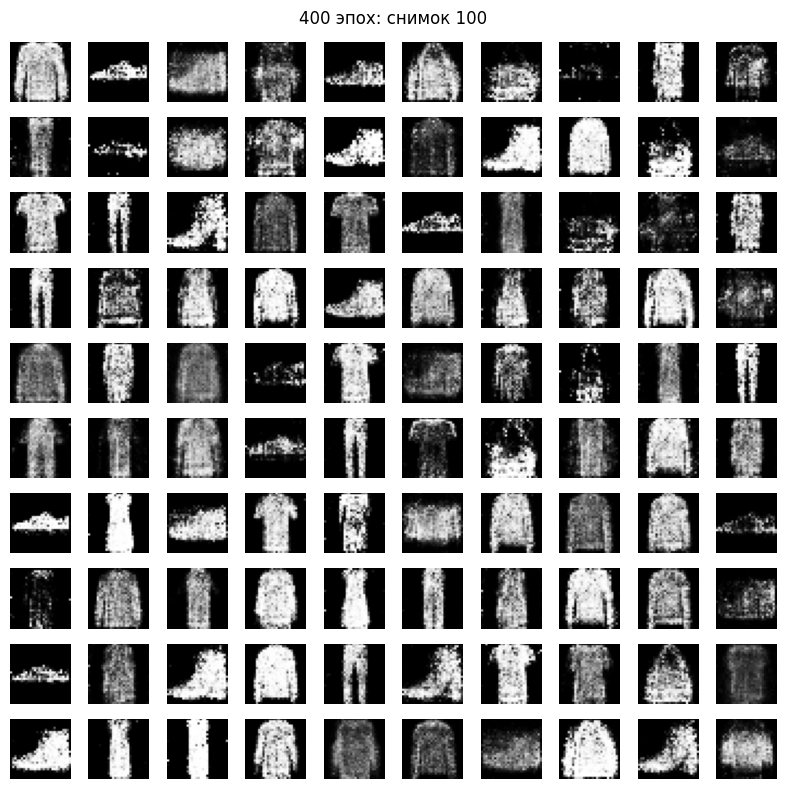

100/400: D=0.59814, G=1.34905


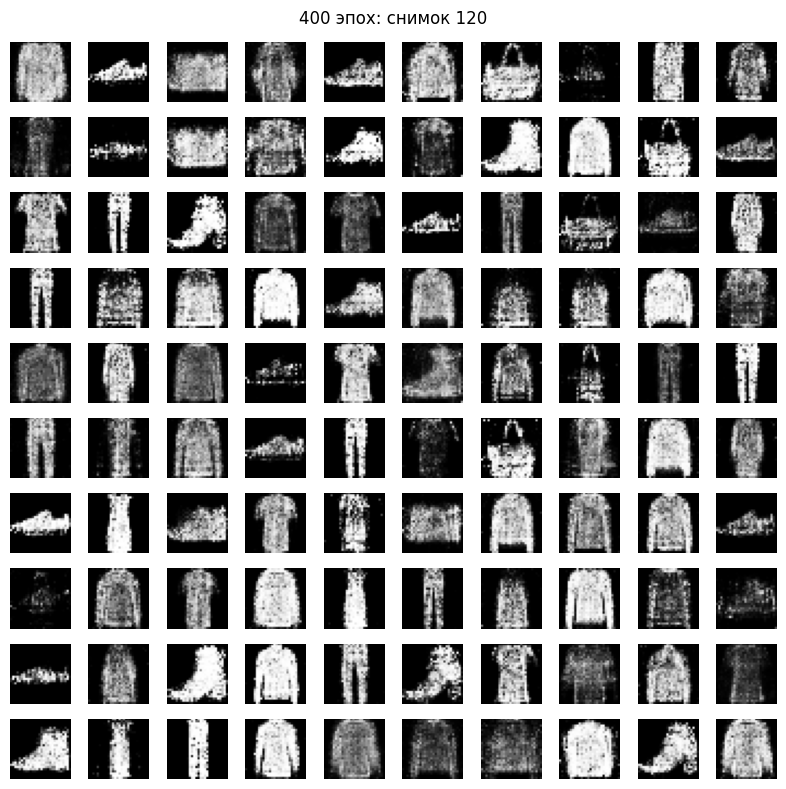

120/400: D=0.62286, G=1.21837


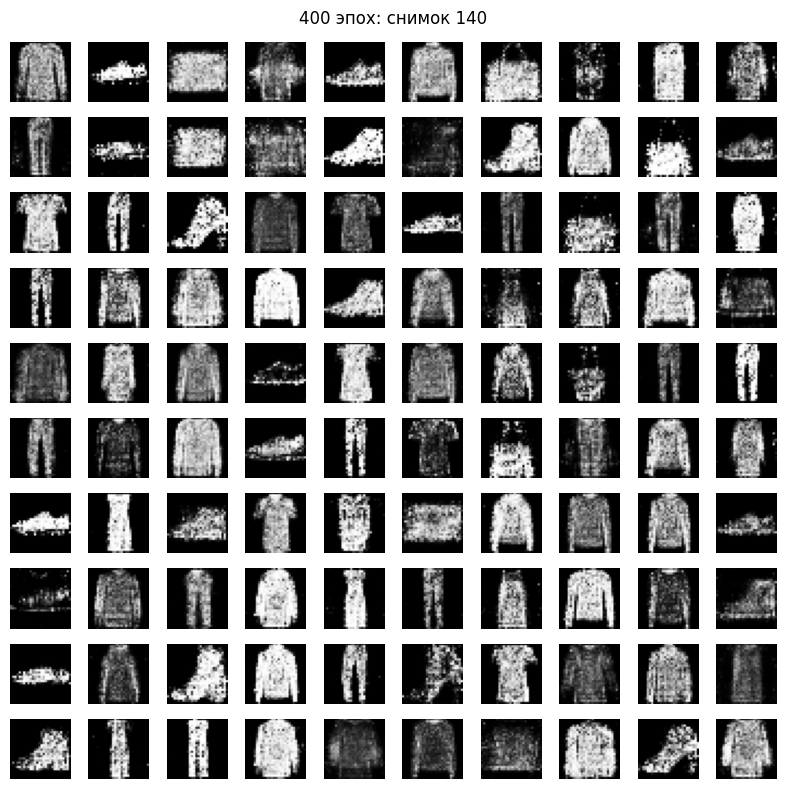

140/400: D=0.62674, G=1.19393


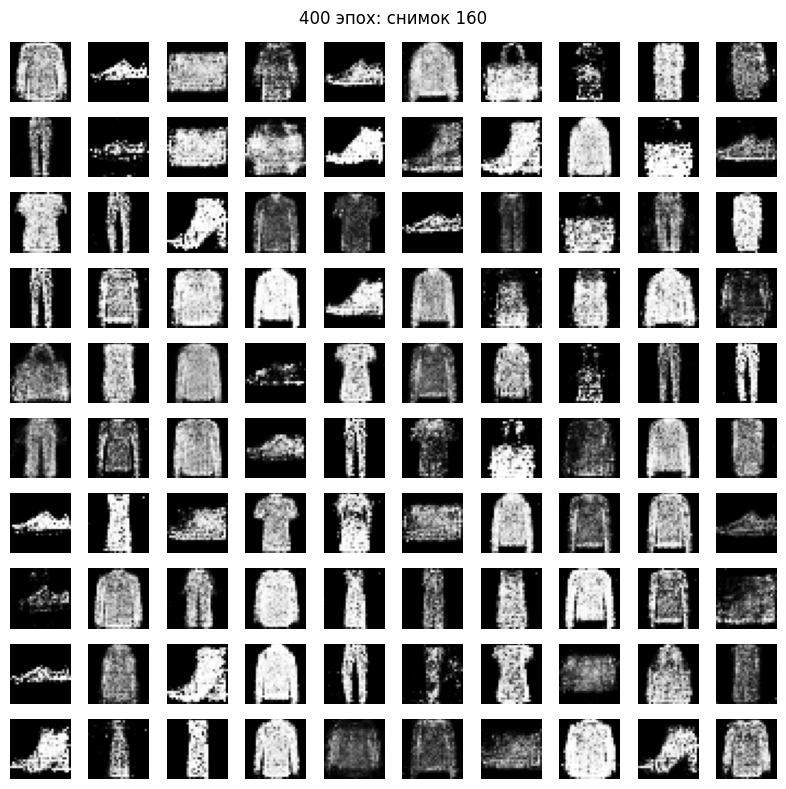

160/400: D=0.63618, G=1.16274


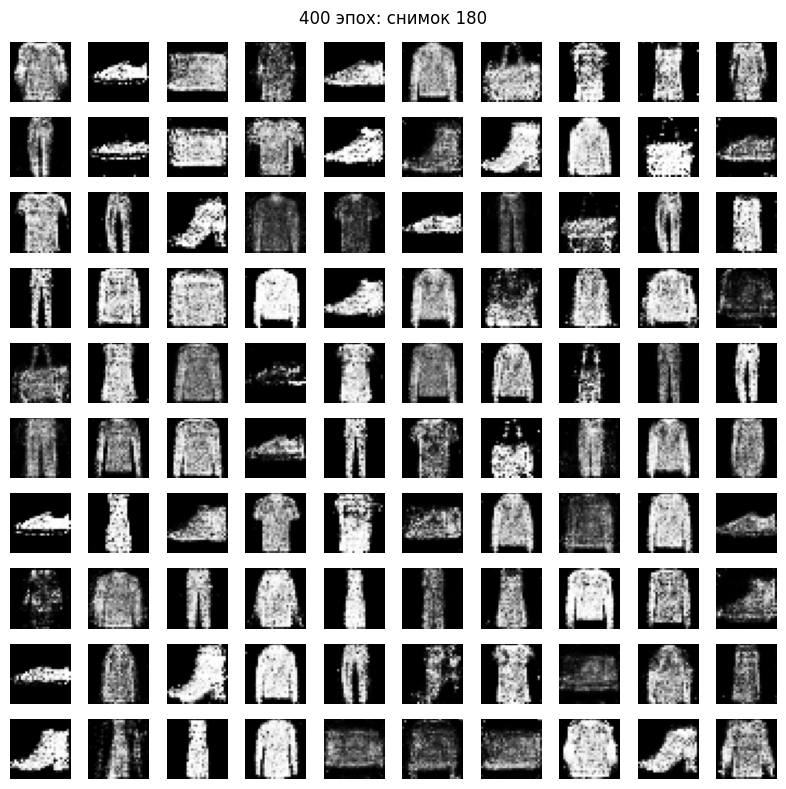

180/400: D=0.63784, G=1.12054


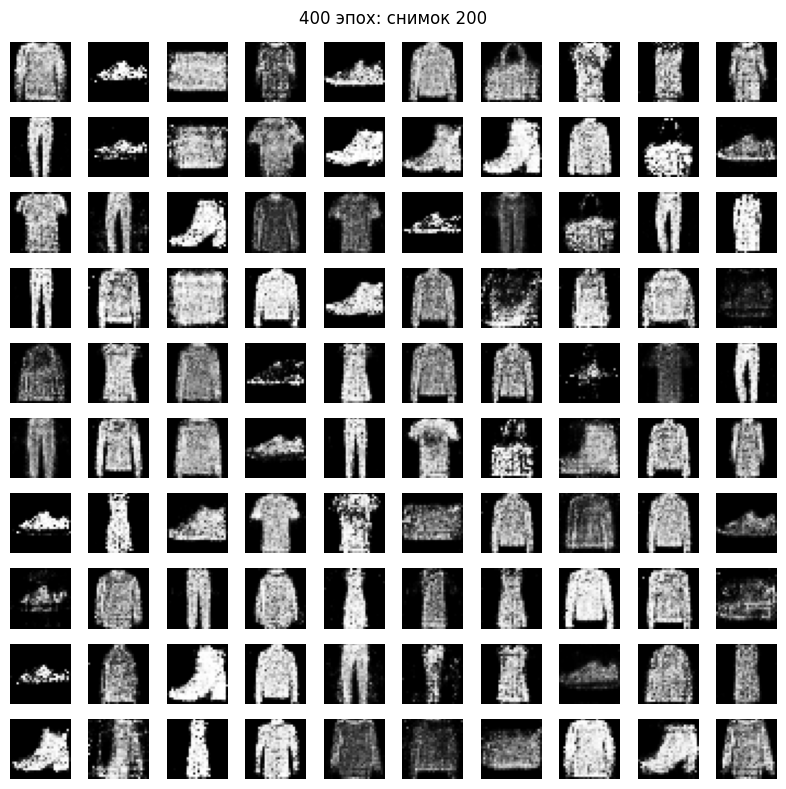

200/400: D=0.63593, G=1.12968


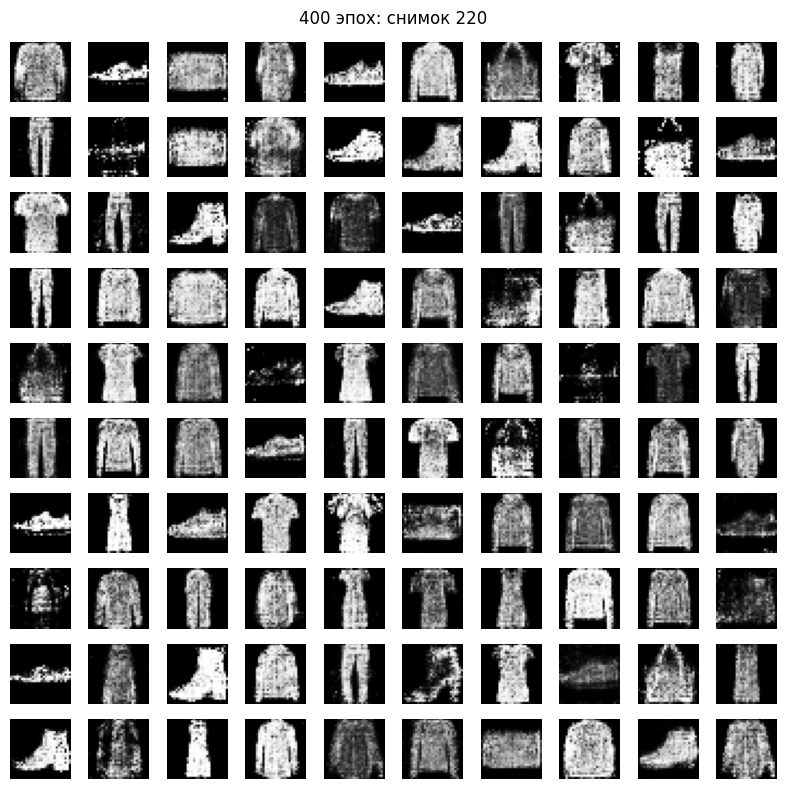

220/400: D=0.63563, G=1.12765


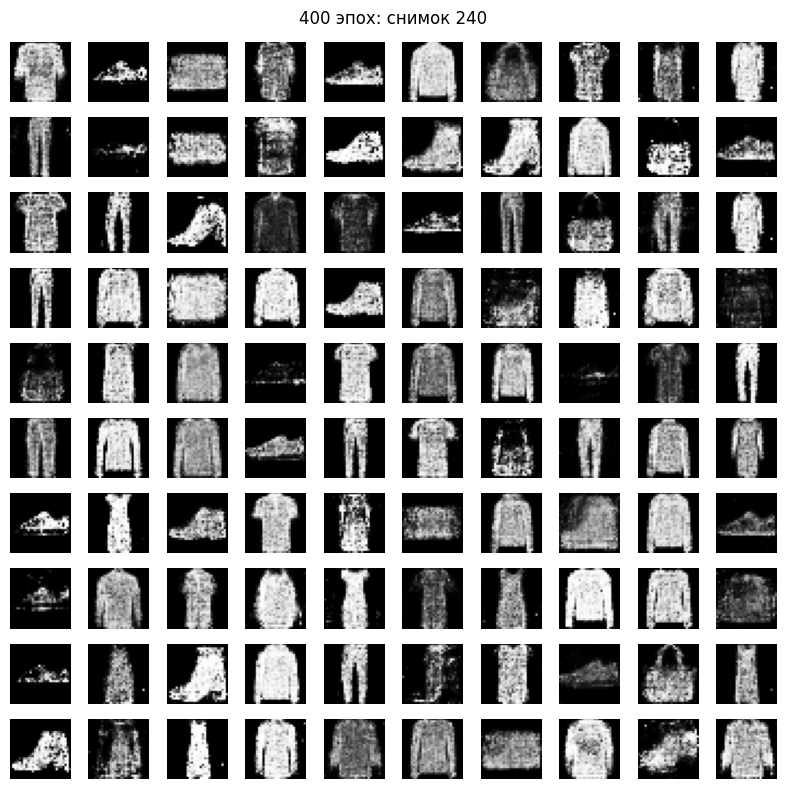

240/400: D=0.63360, G=1.12321


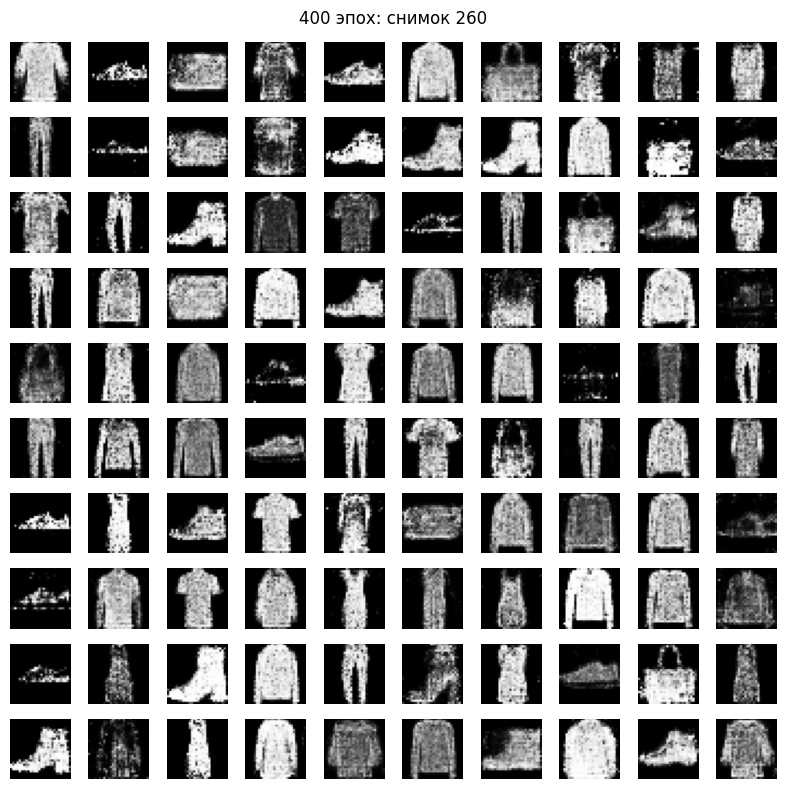

260/400: D=0.63338, G=1.14061


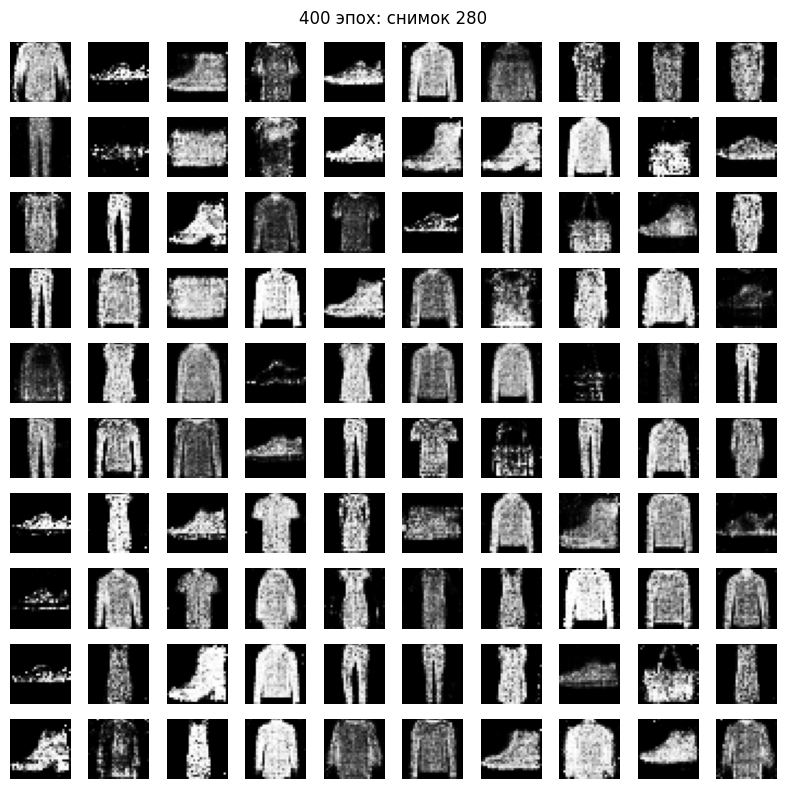

280/400: D=0.63443, G=1.13677


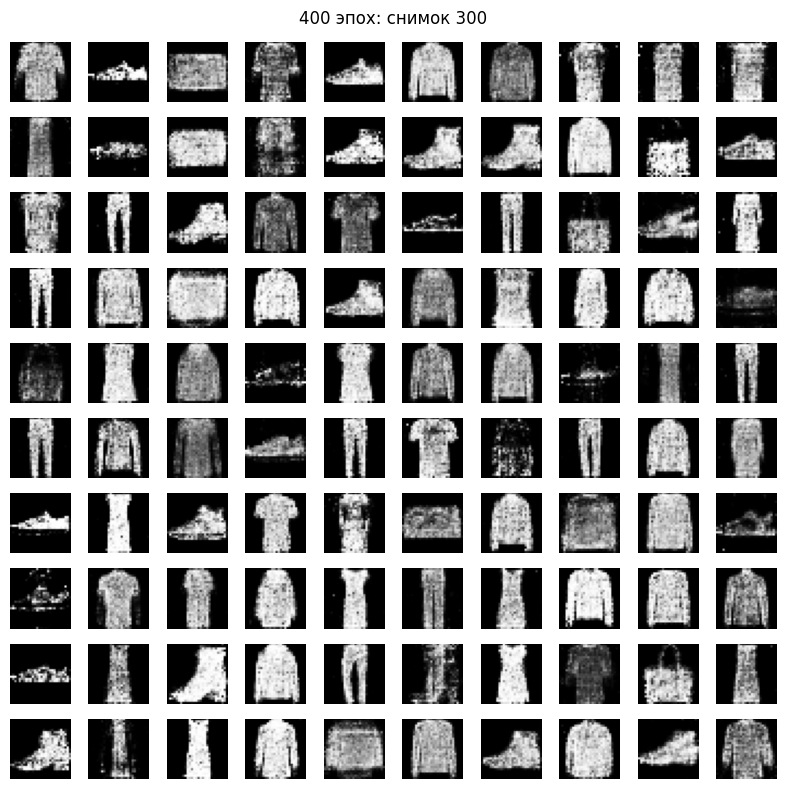

300/400: D=0.63195, G=1.15691


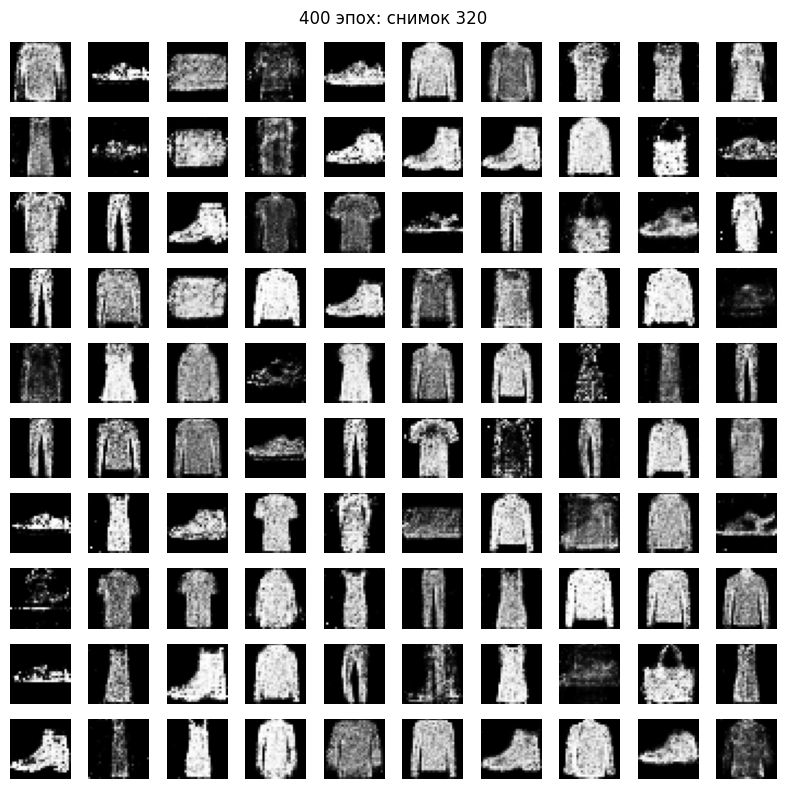

320/400: D=0.62763, G=1.17774


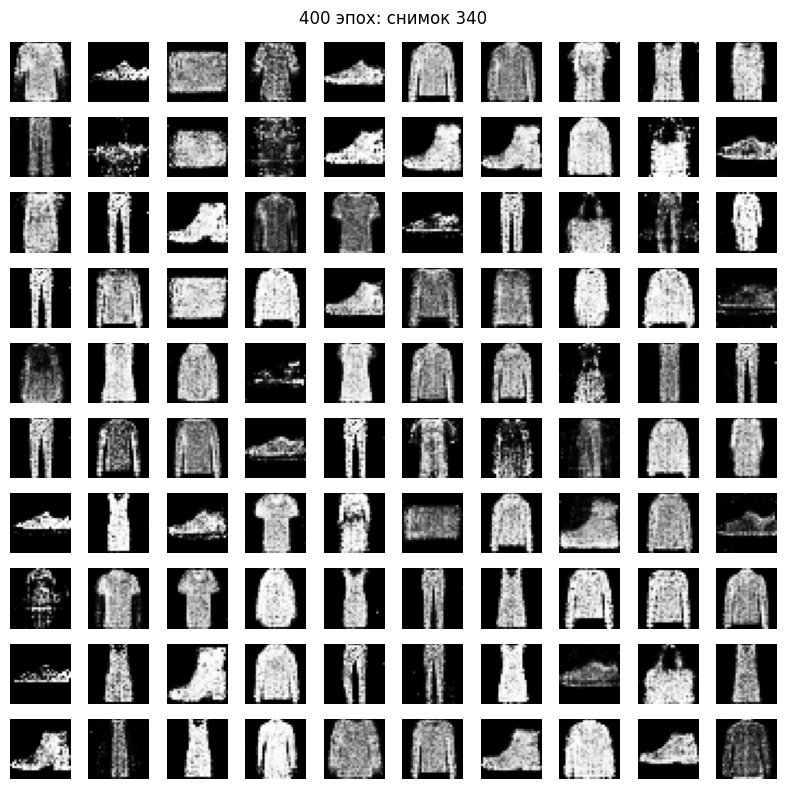

340/400: D=0.62002, G=1.21517


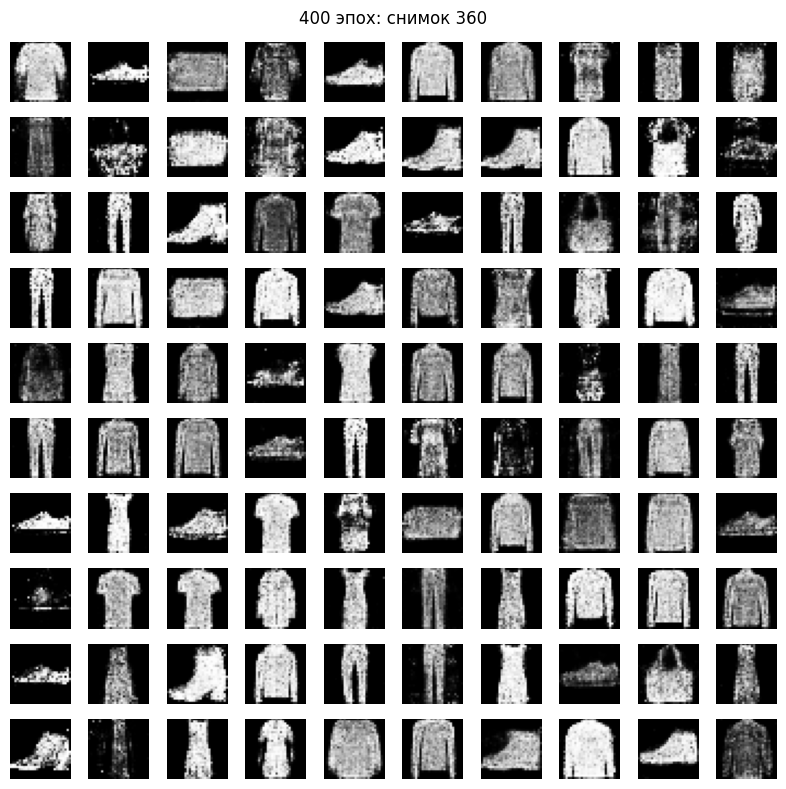

360/400: D=0.62067, G=1.22026


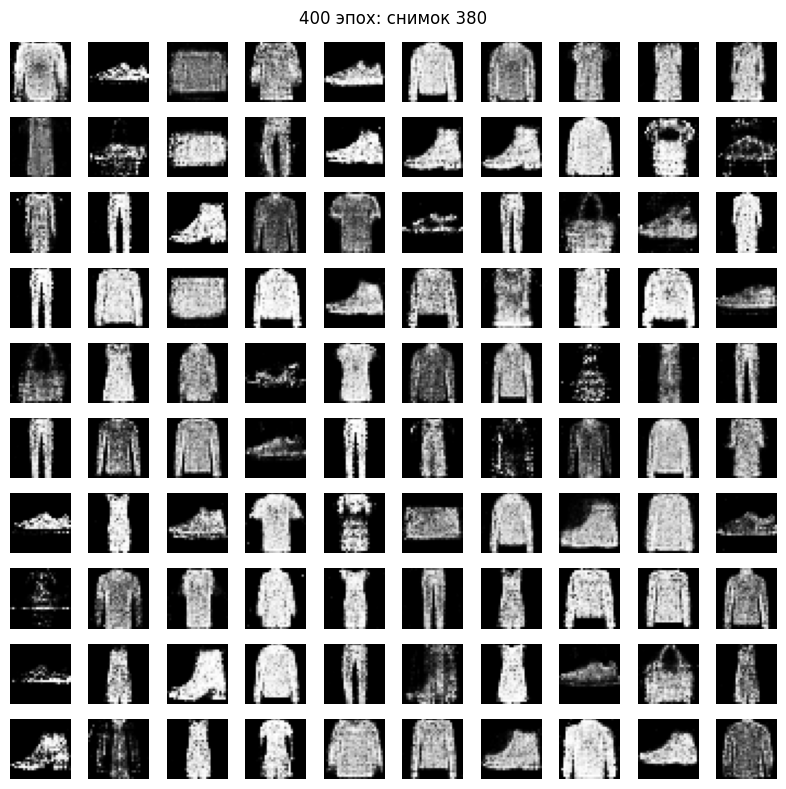

380/400: D=0.62012, G=1.22462


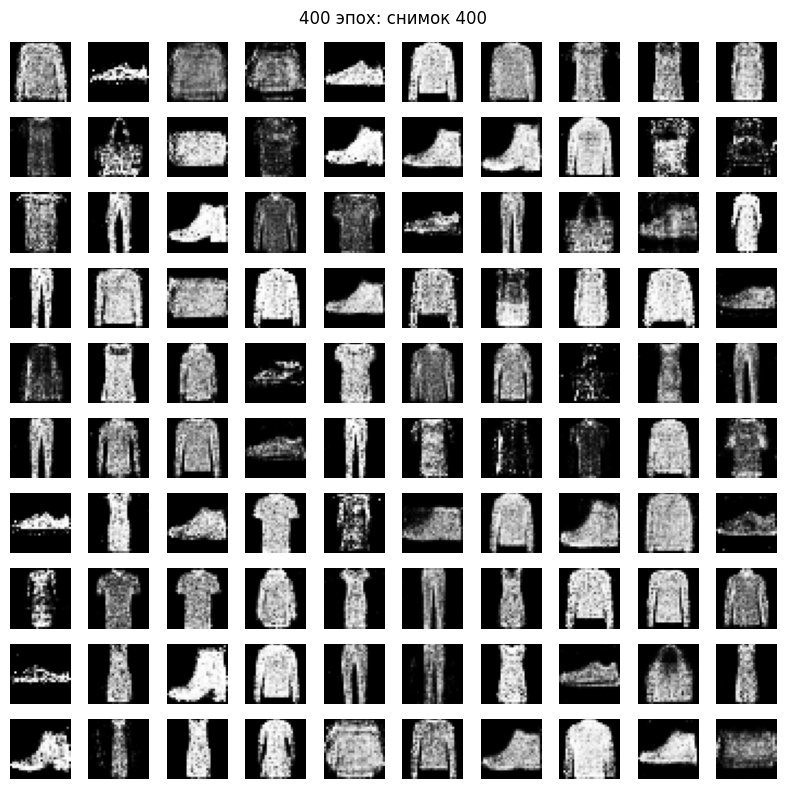

400/400: D=0.61809, G=1.23138


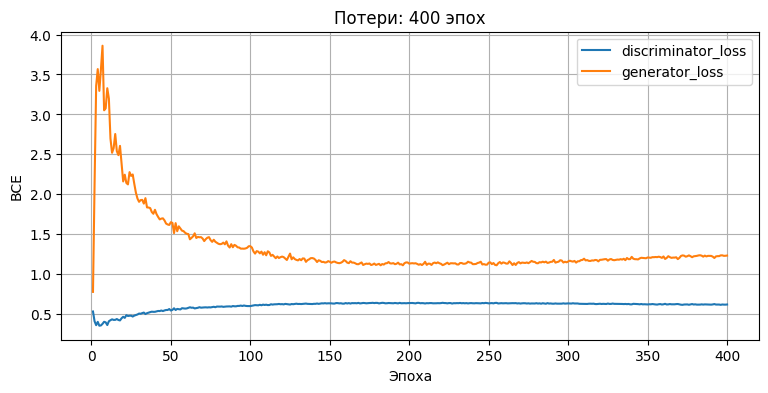

Устройство: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
N= 10000 B= 128 lr= 0.0002 seed= 42
105: D 0.53051 → 0.61703; G 0.77625 → 1.24228; вариация 0.00721 → 0.50282; секунд 117.7
205: D 0.53054 → 0.63853; G 0.77624 → 1.11719; вариация 0.00722 → 0.52296; секунд 199.6
400: D 0.53055 → 0.61809; G 0.77624 → 1.23138; вариация 0.00722 → 0.51558; секунд 378.9


42803

In [6]:
RUNS=[105,205,400]
GRID_SIZE=100
DISPLAY_SHAPE=(28,28)
BASE_DIR=artifact_dir
TRAIN_IMAGES=x_train

fixed_noise=tf.random.stateless_normal((GRID_SIZE,NOISE_DIM),seed=[SEED,17])
results={}
for epochs in RUNS:
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)
    generator,discriminator=make_generator(),make_discriminator()
    train_step,_,_=make_step(generator,discriminator)
    run_dir=BASE_DIR/f'epochs_{epochs}'
    run_dir.mkdir(parents=True,exist_ok=True)
    history={'discriminator_loss':[],'generator_loss':[],'diversity':[]}
    # Новый shuffle с тем же seed для каждого независимого запуска.
    train_data=tf.data.Dataset.from_tensor_slices(TRAIN_IMAGES).shuffle(len(TRAIN_IMAGES),seed=SEED).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
    started=time.perf_counter()
    for epoch in range(1,epochs+1):
        losses=[]
        for real in train_data:
            d,g=train_step(real)
            losses.append([float(d),float(g)])
        d,g=np.mean(losses,axis=0)
        assert np.isfinite([d,g]).all()
        history['discriminator_loss'].append(float(d))
        history['generator_loss'].append(float(g))
        generated=generator(fixed_noise,training=False).numpy()
        assert np.isfinite(generated).all()
        # Среднее стандартное отклонение пикселя между разными шумами — вспомогательная мера вариации.
        history['diversity'].append(float(np.std(generated,axis=0).mean()))
        if epoch==1 or epoch%20==0 or epoch==epochs:
            images=np.clip((generated+1)/2,0,1).reshape((-1,)+DISPLAY_SHAPE)
            side=int(np.sqrt(GRID_SIZE))
            fig,axes=plt.subplots(side,side,figsize=(8,8))
            for ax,img in zip(axes.flat,images):
                ax.imshow(img,cmap='gray' if img.ndim==2 else None,vmin=0,vmax=1); ax.axis('off')
            fig.suptitle(f'{epochs} эпох: снимок {epoch}'); fig.tight_layout()
            fig.savefig(run_dir/f'generated_epoch_{epoch:03d}.png',dpi=120)
            plt.show(); plt.close(fig)
            print(f'{epoch}/{epochs}: D={d:.5f}, G={g:.5f}')
        (run_dir/'history.json').write_text(json.dumps(history),encoding='utf-8')
    elapsed=time.perf_counter()-started
    fig,ax=plt.subplots(figsize=(9,4))
    for key in ['discriminator_loss','generator_loss']: ax.plot(range(1,epochs+1),history[key],label=key)
    ax.set(xlabel='Эпоха',ylabel='BCE',title=f'Потери: {epochs} эпох'); ax.legend(); ax.grid(); fig.savefig(run_dir/'losses.png'); plt.show(); plt.close(fig)
    generator.save_weights(run_dir/'generator.weights.h5')
    results[epochs]={'history':history,'seconds':elapsed,'G_params':generator.count_params(),'D_params':discriminator.count_params()}
print('Устройство:',tf.config.list_physical_devices('GPU') or tf.config.list_physical_devices('CPU'))
print('N=',len(TRAIN_IMAGES),'B=',BATCH_SIZE,'lr=',LEARNING_RATE,'seed=',SEED)
for epochs,r in results.items():
    h=r['history']; print(f"{epochs}: D {h['discriminator_loss'][0]:.5f} → {h['discriminator_loss'][-1]:.5f}; G {h['generator_loss'][0]:.5f} → {h['generator_loss'][-1]:.5f}; вариация {h['diversity'][0]:.5f} → {h['diversity'][-1]:.5f}; секунд {r['seconds']:.1f}")
    assert len(h['generator_loss'])==epochs
(BASE_DIR/'results.json').write_text(json.dumps(results),encoding='utf-8')

## Этап 7. Итоговая самопроверка

- Использован именно Fashion-MNIST, а не MNIST из примера.
- Шум имеет форму $(B,100)$; реальные и синтетические изображения —
  $(B,784)$; ответ дискриминатора — $(B,1)$.
- Реальные значения нормированы к $[-1,1]$, как и выход tanh
  генератора.
- Метки классов одежды не входят в BinaryCrossentropy GAN.
- Генератор и дискриминатор обновляются отдельными оптимизаторами.
- Сетки и две истории потерь сохранены для всех трёх экспериментов.

## Отчёт: методика и анализ

**Цель:** обучить dense GAN на Fashion-MNIST для генерации изображений одежды без использования меток классов и сравнить три независимых эксперимента.

**Параметры:** TensorFlow 2.21.0, GPU (тип устройства по выводу TensorFlow), 10 000 изображений, batch size 128, seed 42, размерность шума 100, Adam с learning rate 0.0002 и beta_1=0.5. Число эпох: 105, 205 и 400.

**Формы:** $(B,100) \to G \to (B,784) \to D \to (B,1)$. Реальные и синтетические изображения лежат в диапазоне $[-1,1]$.

**Потери:** $L_D=(BCE(0.9,D(X))+BCE(0,D(G(Z))))/2$, $L_G=BCE(1,D(G(Z)))$. При шаге D генератор не обновляется; при шаге G градиент проходит через фиксированный D. Раздельное обновление подтверждено диагностической ячейкой.

| Эпохи | D в начале | D в конце | G в начале | G в конце | Вариация в начале | Вариация в конце | Время, с |
|---:|---:|---:|---:|---:|---:|---:|---:|
|105|0.53051|0.61703|0.77625|1.24228|0.00721|0.50282|117.7|
|205|0.53054|0.63853|0.77624|1.11719|0.00722|0.52296|199.6|
|400|0.53055|0.61809|0.77624|1.23138|0.00722|0.51558|378.9|

Общее время: около 696.2 с. Все потери конечны. Сетки фиксированного шума и графики потерь сохранены в выводе предыдущей ячейки.

**Визуальный анализ:** после 105 эпох различимы силуэты одежды и обуви, но заметен шум. После 205 эпох контуры более отчётливы; после 400 эпох также различимы разные предметы, однако однозначного улучшения относительно 205 эпох нет. Полного коллапса мод визуально не наблюдается, хотя отдельные образцы похожи и представлены не все возможные разновидности. Вариация пикселей возрастает относительно первой эпохи во всех запусках, но не является самостоятельной метрикой реалистичности. Конечная потеря D не близка к нулю, что не подтверждает его абсолютное доминирование; баланс меняется во времени.

**Вывод:** 205 эпох дают разумный компромисс между временем, наблюдаемым разнообразием и конечными потерями. Потери GAN не обязаны снижаться монотонно, поскольку обе стороны одновременно меняют свои параметры. Меньшая потеря G сама по себе не доказывает превосходство генератора. Для объективного сравнения качества нужны дополнительные метрики и повторные запуски с другими seed.


## Контрольные вопросы
1. Шум — независимый случайный вектор, задающий вариации синтеза, а не категория объекта.
2. Логит — вещественная оценка до sigmoid; вероятность после sigmoid принадлежит (0,1).
3. Одинаковые формы и диапазоны не позволяют D отличать источники по техническим признакам.
4. 0.9 — сглаженная цель реальных данных, 0 — синтетических на шаге D, 1 — цель G.
5. На шаге G дискриминатор передаёт производную через свои операции, но его параметры фиксированы, иначе изменится целевая функция этого шага.
6. Обе сети изменяют задачу друг друга, поэтому потери могут колебаться.
7. Коллапс мод — потеря разнообразия: разные шумы дают почти одинаковые изображения.
8. GAN безусловная: метки одежды не определяют цель real/fake.
9. DCGAN сохраняет пространственные оси и использует общие локальные ядра; dense GAN смешивает плоские координаты.
10. BCE по логитам объединяет sigmoid и логарифмы численно устойчиво; отдельный sigmoid не нужен.
11. Три копии одного канала содержат одинаковые интенсивности, а не независимую цветовую информацию.
12. Нужны одинаковые данные, шум, параметры обучения, число эпох и сопоставимые сетки; сравнивают также время, число параметров и разнообразие, а не одну потерю.
